# Forecasting U.S. House Elections with Historical Priors

**COSC 274: Machine Learning & Statistical Data Analysis · Final Project**

**Abstract.** This project forecasts U.S. House elections district by district (who wins, and by how much) using only information available before Election Day: the district's previous two results, incumbency, and the national context (midterm year, the president's party, and redistricting). Using MIT Election Data and Science Lab returns for 1976–2024 (about 10,400 modeled races), every model is trained on 1978–2014, tuned on 2016, and evaluated once on the 2018 midterm and on 2022, the first election under post-2020-census district lines. The models compared are logistic regression, a random forest, Naive Bayes, and Bayesian logistic and linear regression. The Bayesian models build their prior from the 1978–1998 elections, with a weight a₀ controlling how much those older elections count relative to 2000–2014. All models rank races almost perfectly (ROC AUC 0.94–0.99) but barely beat a "same party wins again" baseline at calling winners, and the random forest gives the best-calibrated probabilities. On the research question (does treating older elections as a down-weighted prior beat simply pooling all the data?), the answer was no. Pooling was as good or better in nearly every held-out comparison, and down-weighting history led Bayesian logistic regression to expect about 138 Democratic wins in 2022 against 208 actual, because election-level effects such as the midterm penalty are learned from only a handful of recent elections.

**Research question.** Does using older elections as a *prior* produce better-calibrated forecasts than simply pooling all the data together?

For every U.S. House race, this notebook predicts two things using only information available before Election Day:

| Task | Target | Models |
|---|---|---|
| Classification | Does the Democratic candidate win? | Logistic regression, random forest, Naive Bayes with a historical prior, Bayesian logistic regression with a historical prior |
| Regression | Two-party vote margin | Least squares, least absolute deviations (LAD), Bayesian linear regression with a historical prior |

**Data.** MIT Election Data and Science Lab (MEDSL), *U.S. House 1976–2024*, Harvard Dataverse.

**How this notebook fits into the project.**
- `src/build_dataset.py` turns the raw MEDSL returns (one row per candidate) into `data/processed/house_races.csv` (one row per district per election) and computes the features.
- `notebooks/01_explore.ipynb` is the exploratory analysis. Its findings are cited below wherever they motivate a modeling decision.
- This notebook is the main workflow: features, splits, models, evaluation, and conclusions.

**Contents**
1. Setup
2. Data and key findings from the exploratory analysis
3. Features, splits, and the baseline
4. Classification: who wins?
5. Regression: by how much?
6. Research question: historical prior vs. pooled data
7. Final evaluation on the test and stress-test elections
8. Discussion and conclusion
9. References

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression, QuantileRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, brier_score_loss, f1_score, log_loss,
                             mean_absolute_error, mean_squared_error, precision_score,
                             recall_score, roc_auc_score)

SEED = 274

ROOT = Path("..")                                   # notebook lives in notebooks/
DATA = ROOT / "data" / "processed" / "house_races.csv"
RESULTS = ROOT / "results"
FIGS = RESULTS / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

# Experimental design (see README)
PRIOR_YEARS  = list(range(1978, 1999, 2))           # Bayesian models: these elections set the prior
UPDATE_YEARS = list(range(2000, 2015, 2))           # Bayesian models: these elections update it
TRAIN_YEARS  = PRIOR_YEARS + UPDATE_YEARS           # every model sees the same 1978–2014 elections
VAL_YEAR, TEST_YEAR, STRESS_YEAR = 2016, 2018, 2022

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:.3f}".format)

## 2. Data

`src/build_dataset.py` already did the heavy lifting on the raw MEDSL file:

- repaired the quote-wrapped Dataverse export and parsed all 33,805 candidate rows;
- kept, for each seat, the election that actually decided it (regular general, special general, or runoff, which matters for Texas in 1996 and 2006);
- merged New York fusion-ticket lines, dropped ballot artifacts ("BLANK VOTE", "EXHAUSTED BALLOT"), and excluded the D.C. delegate;
- computed the features below, all **signed from the Democratic point of view** (positive favors Democrats, negative favors Republicans), so the models treat the two parties symmetrically.

| Column | Meaning |
|---|---|
| `margin` | two-party margin, (D − R) / (D + R); ±1 when only one major party ran |
| `dem_win` | 1 if the Democrat won (classification target) |
| `contested` | both major parties had a candidate |
| `margin_lag1`, `margin_lag2` | margin in the same district one and two cycles earlier |
| `contested_lag1` | whether the previous race was contested |
| `incumbent` | +1 Democratic incumbent running, −1 Republican incumbent, 0 open seat |
| `midterm`, `pres_party` | midterm year; party of the sitting president (+1 D, −1 R) |
| `midterm_x_pres` | midterm × president's party: the midterm-penalty term |
| `redistrict_year` | first election under new post-census district lines |

In [2]:
if not DATA.exists():
    raise FileNotFoundError(f"{DATA} not found. From the repo root, run: "
                            "python src/build_dataset.py --input data/raw/<medsl file>")

races = pd.read_csv(DATA)
per_year = races.groupby("year").size()
assert (per_year == 435).all(), "Expected 435 races in every cycle; rerun src/build_dataset.py"

print(f"{len(races):,} races across {races['year'].nunique()} cycles "
      f"({races['year'].min()}–{races['year'].max()}), 435 per cycle")
races.head()

10,875 races across 25 cycles (1976–2024), 435 per cycle


,year,state_po,district,total_votes,d_votes,r_votes,winner_party,decided_by,margin,contested,dem_win,margin_lag1,contested_lag1,margin_lag2,contested_lag2,incumbent,midterm,pres_party,midterm_x_pres,redistrict_year
0,1976,AK,0,118208,34194.000,83722.000,R,general,-0.420,True,0,NaN,NaN,NaN,NaN,0,0,-1,0,0
1,1978,AK,0,124187,55176.000,68811.000,R,general,-0.110,True,0,-0.420,True,NaN,NaN,-1,1,1,1,0
2,1980,AK,0,154618,39922.000,114089.000,R,general,-0.482,True,0,-0.110,True,-0.420,True,-1,0,1,0,0
3,1982,AK,0,181084,52011.000,128274.000,R,general,-0.423,True,0,-0.482,True,-0.110,True,-1,1,-1,-1,1
4,1984,AK,0,206437,86052.000,113582.000,R,general,-0.138,True,0,-0.423,True,-0.482,True,-1,0,-1,0,0


### 2.1 Key findings from the exploratory analysis

The full exploratory analysis is in `notebooks/01_explore.ipynb`. Three of its findings shape the modeling choices in this notebook, and the figure below reproduces them from the same data.

The middle and right panels use races contested in both the current and the previous cycle, and leave out the first election after each census (1982, 1992, 2002, 2012, 2022), when district numbers were reused for differently drawn districts.

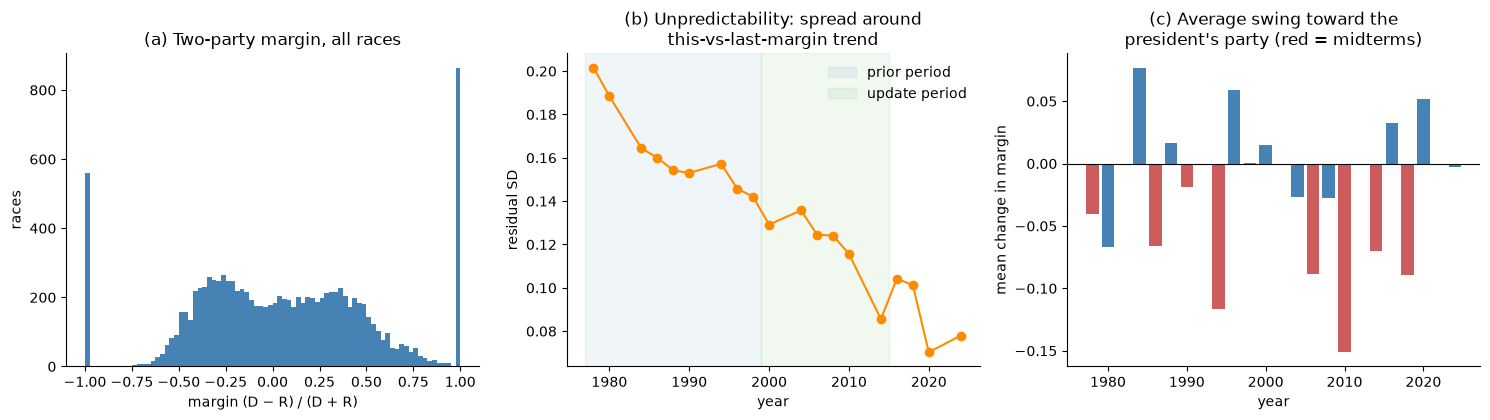

Uncontested races: 13.1% of all races
Spread around the trend: 0.20 in 1978, 0.08 in 2024
Average swing toward the president's party: midterms -0.071, presidential years +0.013


In [3]:
r = races.copy()
for col in ["contested", "contested_lag1"]:
    r[col] = r[col].astype(str).str.upper().eq("TRUE")
both = r[r["contested"] & r["contested_lag1"] & (r["redistrict_year"] == 0) & (r["winner_party"] != "O")]

resid_sd = {}
for yr, sub in both.groupby("year"):
    slope, intercept = np.polyfit(sub["margin_lag1"], sub["margin"], 1)
    resid_sd[yr] = (sub["margin"] - (intercept + slope * sub["margin_lag1"])).std()
resid_sd = pd.Series(resid_sd)
swing = ((both["margin"] - both["margin_lag1"]) * both["pres_party"]).groupby(both["year"]).mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
axes[0].hist(r["margin"].dropna(), bins=80, color="steelblue")
axes[0].set(title="(a) Two-party margin, all races", xlabel="margin (D − R) / (D + R)", ylabel="races")

axes[1].plot(resid_sd.index, resid_sd.values, marker="o", color="darkorange")
axes[1].axvspan(1977, 1999, color="tab:blue", alpha=0.07, label="prior period")
axes[1].axvspan(1999, 2015, color="tab:green", alpha=0.07, label="update period")
axes[1].set(title="(b) Unpredictability: spread around\nthis-vs-last-margin trend", xlabel="year", ylabel="residual SD")
axes[1].legend(frameon=False)

axes[2].bar(swing.index, swing.values, width=1.6,
            color=["indianred" if yr % 4 == 2 else "steelblue" for yr in swing.index])
axes[2].axhline(0, color="black", linewidth=0.8)
axes[2].set(title="(c) Average swing toward the\npresident's party (red = midterms)", xlabel="year",
            ylabel="mean change in margin")
fig.tight_layout(); fig.savefig(FIGS / "exploration_summary.png", dpi=150)
plt.show()

print(f"Uncontested races: {1 - r['contested'].mean():.1%} of all races")
print(f"Spread around the trend: {resid_sd.iloc[0]:.2f} in {resid_sd.index[0]}, {resid_sd.iloc[-1]:.2f} in {resid_sd.index[-1]}")
print(f"Average swing toward the president's party: midterms {swing[swing.index % 4 == 2].mean():+.3f}, "
      f"presidential years {swing[swing.index % 4 == 0].mean():+.3f}")

**(a) Uncontested races** appear as spikes at margins of exactly ±1. Their margin says nothing about how competitive a district is, so the regression models are trained on contested races only (Section 5), and Section 5.2 tests what happens if they are left in.

**(b) Results have become much more predictable.** The scatter of this election's margin around what last election's margin predicts has roughly halved since the late 1970s. This is central to the research question: the older elections are noisier, so a model that leans on them may be *less confident than it should be* today, while a model that ignores them has less data for the effects they could still inform. It is also why the Bayesian regression takes its noise level from recent elections (Section 5.3).

**(c) The midterm penalty is large and consistent.** In midterm years, districts swing several points away from the president's party on average, versus little change in presidential years. This motivates the `midterm_x_pres` feature, and it turns out to be the effect where the choice of prior matters most (Sections 4.5 and 7).

## 3. Features, splits, and the baseline

### 3.1 The modeling table

Three preparation steps:

1. **Drop races with no previous result in the district.** That is every 1976 race (there is no 1974 data) plus districts newly created after reapportionment. Without `margin_lag1` there is nothing to forecast from.
2. **Fill missing two-cycle lags.** When `margin_lag2` is unavailable it is set equal to `margin_lag1`, and a `has_lag2` flag records that it was filled.
3. **Flag competitive races for evaluation.** A race is *competitive* if it was contested and decided by fewer than 10 points. This uses the actual result, so it is only ever used to slice the evaluation, never as a feature.

Races won by a third-party or independent candidate (12 in total, 8 of them Bernie Sanders's Vermont seat) are excluded, since neither class describes them.

In [4]:
FEATURES = ["margin_lag1", "margin_lag2", "has_lag2", "contested_lag1",
            "incumbent", "midterm", "pres_party", "midterm_x_pres", "redistrict_year"]

def as_int_flag(s):
    # CSV booleans can load as bools or strings depending on missing values; normalise to 0/1.
    return s.astype(str).str.upper().eq("TRUE").astype(int)

df = races.copy()
df["contested"] = as_int_flag(df["contested"]).astype(bool)

no_lag = df["margin_lag1"].isna()
third_party = df["winner_party"] == "O"
df = df[~no_lag & ~third_party].copy()

df["has_lag2"] = df["margin_lag2"].notna().astype(int)
df["margin_lag2"] = df["margin_lag2"].fillna(df["margin_lag1"])
df["contested_lag1"] = as_int_flag(df["contested_lag1"])
df["competitive"] = df["contested"] & (df["margin"].abs() < 0.10)

print(f"Dropped {no_lag.sum():,} races with no previous result and "
      f"{(third_party & ~no_lag).sum()} third-party wins; {len(df):,} races remain.")
df[FEATURES].describe().T[["mean", "std", "min", "max"]]

Dropped 508 races with no previous result and 12 third-party wins; 10,355 races remain.


,mean,std,min,max
margin_lag1,0.065,0.488,-1.000,1.000
margin_lag2,0.074,0.489,-1.000,1.000
has_lag2,0.951,0.216,0.000,1.000
contested_lag1,0.867,0.339,0.000,1.000
incumbent,0.065,0.906,-1.000,1.000
midterm,0.500,0.500,0.000,1.000
pres_party,0.003,1.000,-1.000,1.000
midterm_x_pres,0.002,0.707,-1.000,1.000
redistrict_year,0.203,0.402,0.000,1.000


### 3.2 Splits

The splits are by **time**, never random, because the real task is forecasting a future election from past ones. Hyperparameters are chosen on 2016 only. The 2018 test election and the 2022 stress test are not touched until Section 7.

2022 is a deliberate stress test: it was the first election under post-2020-census maps, so most districts' `margin_lag1` describes a differently drawn district.

In [5]:
def years(data, yrs):
    yrs = yrs if isinstance(yrs, list) else [yrs]
    return data[data["year"].isin(yrs)]

split_years = {
    "prior (1978-1998)":   PRIOR_YEARS,
    "update (2000-2014)":  UPDATE_YEARS,
    "train (1978-2014)":   TRAIN_YEARS,
    "validation (2016)":   VAL_YEAR,
    "test (2018)":         TEST_YEAR,
    "stress test (2022)":  STRESS_YEAR,
}
pd.DataFrame({
    name: {"races": len(s := years(df, y)),
           "Democratic win rate": s["dem_win"].mean(),
           "contested share": s["contested"].mean(),
           "competitive share": s["competitive"].mean()}
    for name, y in split_years.items()
}).T

,races,Democratic win rate,contested share,competitive share
prior (1978-1998),4738.000,0.566,0.855,0.141
update (2000-2014),3452.000,0.486,0.864,0.114
train (1978-2014),8190.000,0.532,0.858,0.129
validation (2016),435.000,0.446,0.853,0.074
test (2018),434.000,0.539,0.908,0.205
stress test (2022),426.000,0.488,0.918,0.162


### 3.3 Evaluation metrics and the baseline

Because most districts are safe, plain accuracy flatters every model (Lecture 7). Each classifier is therefore scored on:

- **log loss** (cross-entropy) and **Brier score**: how good the predicted probabilities are, not just the labels;
- **ROC AUC**: how well the model ranks Democratic wins above Republican wins;
- **calibration error (ECE)**: the average gap between predicted probability and observed win rate, across 10 probability bins. This is the measure most directly tied to the research question;
- **accuracy on all races** and **accuracy on competitive races**, where the real difficulty is;
- **macro F1** (the average of the F1 scores for each party, so neither party counts as "the positive class"), plus precision and recall for Democratic wins.

The **baseline** predicts that whichever party won the district last time wins again. It outputs labels, not probabilities, so its probability-based metrics are left blank.

In [6]:
def expected_calibration_error(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1)
    return sum(abs(y[idx == b].mean() - p[idx == b].mean()) * (idx == b).mean()
               for b in range(bins) if (idx == b).any())

def clf_metrics(data, p=None, yhat=None):
    # p: predicted P(Democrat wins). Pass yhat instead for models that only output labels.
    y = data["dem_win"].to_numpy()
    comp = data["competitive"].to_numpy()
    yhat = (p >= 0.5).astype(int) if yhat is None else np.asarray(yhat).astype(int)
    m = {
        "log loss":               log_loss(y, p) if p is not None else np.nan,
        "Brier score":            brier_score_loss(y, p) if p is not None else np.nan,
        "ROC AUC":                roc_auc_score(y, p) if p is not None else np.nan,
        "calibration error":      expected_calibration_error(y, p) if p is not None else np.nan,
        "accuracy":               accuracy_score(y, yhat),
        "accuracy (competitive)": accuracy_score(y[comp], yhat[comp]),
        "macro F1":               f1_score(y, yhat, average="macro"),
        "precision (D win)":      precision_score(y, yhat),
        "recall (D win)":         recall_score(y, yhat),
    }
    return m

def baseline_labels(data):
    return (data["margin_lag1"] > 0).astype(int).to_numpy()

train, val = years(df, TRAIN_YEARS), years(df, VAL_YEAR)

pd.DataFrame({
    "baseline, train 1978–2014": clf_metrics(train, yhat=baseline_labels(train)),
    "baseline, validation 2016": clf_metrics(val, yhat=baseline_labels(val)),
}).T

,log loss,Brier score,ROC AUC,calibration error,accuracy,accuracy (competitive),macro F1,precision (D win),recall (D win)
"baseline, train 1978–2014",NaN,NaN,NaN,NaN,0.913,0.624,0.912,0.908,0.931
"baseline, validation 2016",NaN,NaN,NaN,NaN,0.972,0.750,0.972,0.984,0.954


The baseline is strong: it calls about 91% of 1978–2014 races and 97% of 2016 races correctly. 2016 was a status-quo year in which few seats changed hands, which is exactly when "same party wins again" works best. Its weakness is competitive races, where it is right only about 62% of the time in training. Those are the races where a model has to add something.

One caution for everything that follows: 2016 has only 32 competitive races, so each one moves competitive accuracy by about 3 points. Differences of a race or two on that slice are noise, which is one more reason to tune on log loss rather than accuracy.

## 4. Classification: who wins?

All classifiers train on the same 1978–2014 elections and are tuned on 2016 by **validation log loss**, since well-calibrated probabilities are the goal. (The Bayesian classifiers in Sections 4.4 and 4.5 use those same elections, split into a prior period and an update period.)

In [7]:
def Xy(data, target):
    return data[FEATURES].to_numpy(dtype=float), data[target].to_numpy()

X_tr, y_tr = Xy(train, "dem_win")
X_val, y_val = Xy(val, "dem_win")
print(f"train: {X_tr.shape[0]:,} races × {X_tr.shape[1]} features   validation: {X_val.shape[0]:,} races")

train: 8,190 races × 9 features   validation: 435 races


### 4.1 Logistic regression (cross-entropy loss)

Logistic regression models P(Democrat wins) = σ(x̃ᵀw) and is fit by minimizing cross-entropy (Lecture 6). scikit-learn adds an L2 penalty whose strength is set by `C`, where **C = 1/λ**: small `C` means strong regularization (Lecture 5). Features are standardized first, so the penalty treats them equally and the coefficients are comparable.

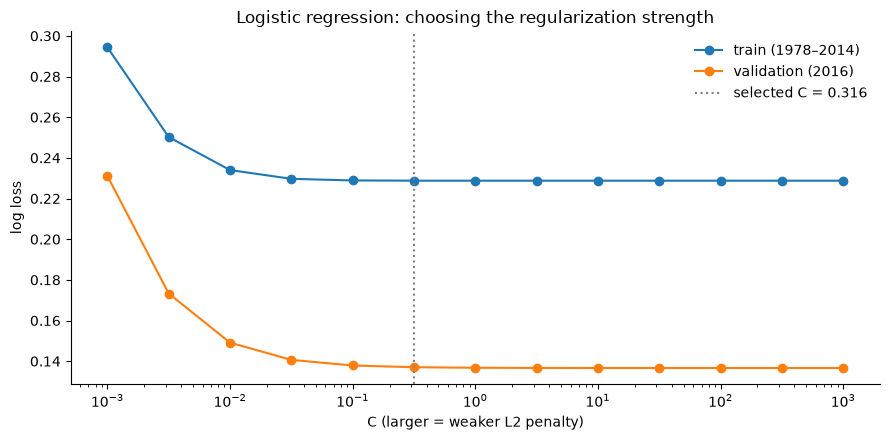

Selected C = 0.316


In [8]:
Cs = np.logspace(-3, 3, 13)
rows = []
for C in Cs:
    model = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000))
    model.fit(X_tr, y_tr)
    rows.append({"C": C,
                 "train log loss": log_loss(y_tr, model.predict_proba(X_tr)[:, 1]),
                 "validation log loss": log_loss(y_val, model.predict_proba(X_val)[:, 1])})
lr_tuning = pd.DataFrame(rows)
# Validation loss flattens out once the penalty is weak, so pick the strongest regularization
# (smallest C) whose validation loss is within 0.001 of the best: simpler model, same performance.
tol = lr_tuning["validation log loss"].min() + 0.001
best_C = lr_tuning.loc[lr_tuning["validation log loss"] <= tol, "C"].min()

fig, ax = plt.subplots()
ax.semilogx(lr_tuning["C"], lr_tuning["train log loss"], marker="o", label="train (1978–2014)")
ax.semilogx(lr_tuning["C"], lr_tuning["validation log loss"], marker="o", label="validation (2016)")
ax.axvline(best_C, color="gray", linestyle=":", label=f"selected C = {best_C:.3g}")
ax.set(title="Logistic regression: choosing the regularization strength",
       xlabel="C (larger = weaker L2 penalty)", ylabel="log loss")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGS / "lr_tuning.png", dpi=150)
plt.show()

lr = make_pipeline(StandardScaler(), LogisticRegression(C=best_C, max_iter=5000)).fit(X_tr, y_tr)
print(f"Selected C = {best_C:.3g}")

**What the model learned.** Because the features are standardized, each coefficient is the change in the log-odds of a Democratic win for a one-standard-deviation increase in that feature.

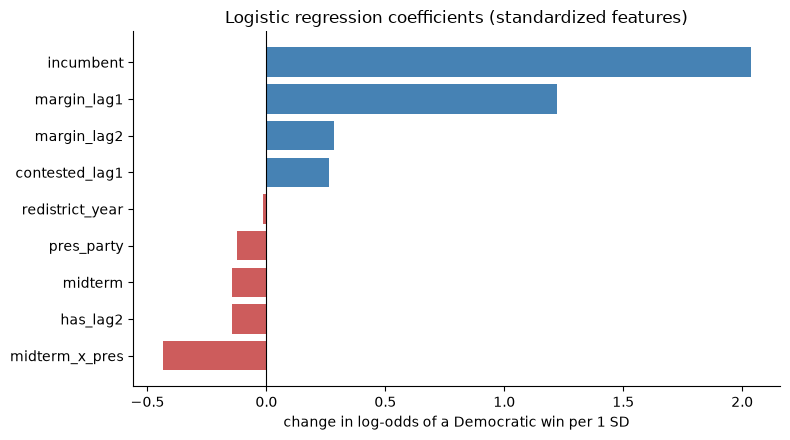

,coefficient
incumbent,2.035
margin_lag1,1.223
margin_lag2,0.283
contested_lag1,0.265
redistrict_year,-0.014
pres_party,-0.123
midterm,-0.144
has_lag2,-0.146
midterm_x_pres,-0.436


In [9]:
lr_coefs = pd.Series(lr[-1].coef_[0], index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(lr_coefs.index, lr_coefs.values, color=["indianred" if v < 0 else "steelblue" for v in lr_coefs])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Logistic regression coefficients (standardized features)",
       xlabel="change in log-odds of a Democratic win per 1 SD")
fig.tight_layout(); fig.savefig(FIGS / "lr_coefficients.png", dpi=150)
plt.show()

lr_coefs.to_frame("coefficient").iloc[::-1]

Three things stand out:

- **Incumbency is the strongest predictor**, followed by the previous margin. Together they carry most of the signal, consistent with the exploratory analysis.
- **The midterm penalty is clearly negative**, as expected. `midterm_x_pres` is +1 in a midterm under a Democratic president, so a negative coefficient means Democrats do worse in those years and better in midterms under a Republican president. This matches the swing found in `01_explore.ipynb`, Section 5.
- **The redistricting flag adds almost nothing on its own.** Its real effect should be to make the model trust `margin_lag1` less in redistricting years, which is an interaction a linear model can't express without being given it explicitly. That is one motivation for the random forest.

The selected regularization is moderate: validation log loss is flat for any C above about 0.3, because with only nine features and over 8,000 races the model has little room to overfit. Validation log loss is also *lower* than training log loss, which simply reflects that 2016 was an easier year to predict than the 1978–2014 average.

### 4.2 Random forest

A random forest averages many decision trees, each grown on a bootstrap sample of the races with a random subset of features considered at each split. Unlike logistic regression it can learn **interactions** without being told about them, for example that incumbency matters more in close districts than in safe ones. Trees don't need standardized features.

Two hyperparameters control how complex each tree can get: the maximum depth, and the minimum number of races allowed in a leaf. Both are tuned on 2016.

In [10]:
rf_rows = []
for depth in [3, 5, 8, 12, None]:
    for leaf in [1, 10, 50]:
        model = RandomForestClassifier(n_estimators=300, max_depth=depth, min_samples_leaf=leaf,
                                       random_state=SEED, n_jobs=-1).fit(X_tr, y_tr)
        rf_rows.append({"max_depth": "none" if depth is None else depth, "min_samples_leaf": leaf,
                        "train log loss": log_loss(y_tr, model.predict_proba(X_tr)[:, 1]),
                        "validation log loss": log_loss(y_val, model.predict_proba(X_val)[:, 1])})
rf_tuning = pd.DataFrame(rf_rows)
best = rf_tuning.loc[rf_tuning["validation log loss"].idxmin()]
best_depth = None if best["max_depth"] == "none" else int(best["max_depth"])
best_leaf = int(best["min_samples_leaf"])

rf = RandomForestClassifier(n_estimators=500, max_depth=best_depth, min_samples_leaf=best_leaf,
                            random_state=SEED, n_jobs=-1).fit(X_tr, y_tr)
print(f"Selected max_depth = {best['max_depth']}, min_samples_leaf = {best_leaf}")
rf_tuning.pivot(index="max_depth", columns="min_samples_leaf", values="validation log loss")

Selected max_depth = 8, min_samples_leaf = 1


min_samples_leaf,1,10,50
max_depth,,,
3,0.149,0.149,0.148
5,0.129,0.129,0.128
8,0.124,0.125,0.126
12,0.141,0.130,0.127
none,0.280,0.130,0.127


The tuning grid shows the usual trade-off between underfitting and overfitting. Shallow trees (depth 3) underfit. Fully grown trees with single-race leaves overfit badly: validation log loss more than doubles, because pure leaves output probabilities of exactly 0 or 1, and cross-entropy punishes a confident wrong prediction very heavily. Moderate depth works best, and at that depth the leaf size barely matters.

**Which features does the forest rely on?** Permutation importance shuffles one feature at a time in the 2016 validation data and measures how much the log loss gets worse. Unlike the forest's built-in importances, it is measured on held-out data.

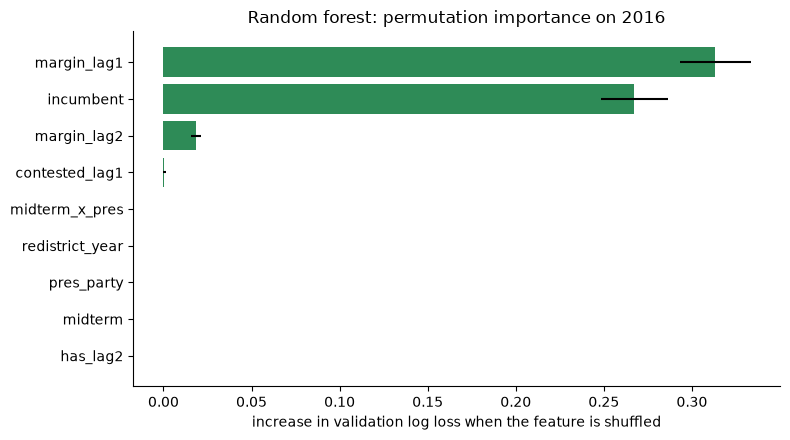

In [11]:
perm = permutation_importance(rf, X_val, y_val, scoring="neg_log_loss", n_repeats=20, random_state=SEED)
rf_importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(rf_importance.index, rf_importance.values, xerr=perm.importances_std[rf_importance.index.map(FEATURES.index)],
        color="seagreen")
ax.set(title="Random forest: permutation importance on 2016",
       xlabel="increase in validation log loss when the feature is shuffled")
fig.tight_layout(); fig.savefig(FIGS / "rf_importance.png", dpi=150)
plt.show()

**Important caveat when reading this chart.** The national features (`midterm`, `pres_party`, `midterm_x_pres`, `redistrict_year`) take the same value for every race in a single election, so shuffling them within 2016 changes nothing and their importance is zero *by construction*. This chart can only rank the district-level features: the previous margin and incumbency dominate, the two-cycle lag adds a little, and the rest add almost nothing. The national features' effects are better judged from the logistic regression coefficients in Section 4.1.

### 4.3 Bayesian learning with a historical prior: the Beta–Bernoulli model

Lectures 13–14 introduced Bayesian learning with the thumbtack example: instead of a single estimate of θ = P(heads), we keep a distribution over θ, update it with data using Bayes' rule, and use a **Beta prior** because it is conjugate to the Bernoulli likelihood:

P(θ | D) ∝ P(D | θ) P(θ),  and with a Beta(β_H, β_T) prior and α_H heads, α_T tails observed, the posterior is **Beta(α_H + β_H, α_T + β_T)**.

The prior's parameters act as **pseudo-counts**: imaginary flips observed before the real data. That gives a direct way to follow the professor's suggestion of building the prior from historical data: *use the outcomes of the older elections as the pseudo-counts.*

As a first example, let θ be the probability that **the incumbent's party holds the seat** when an incumbent runs:

- **Prior** from 1978–1998: β_H = holds, β_T = losses in those elections (plus 1 each, a uniform Beta(1, 1) starting point).
- **Data** from 2000–2014: α_H holds and α_T losses.
- **Prior weight a₀** scales the historical pseudo-counts: a₀ = 1 counts every old race as fully as a new one, and a₀ = 0.1 counts each old race as a tenth of a race. This same weight is used by every Bayesian model in this notebook.

With a uniform prior (a₀ = 0), the posterior mean is essentially the maximum-likelihood estimate (the observed rate), as the lecture showed.

1978–1998 (prior):  3,757 holds, 178 losses  -> rate 0.955
2000–2014 (data):   2,739 holds, 132 losses  -> rate 0.954


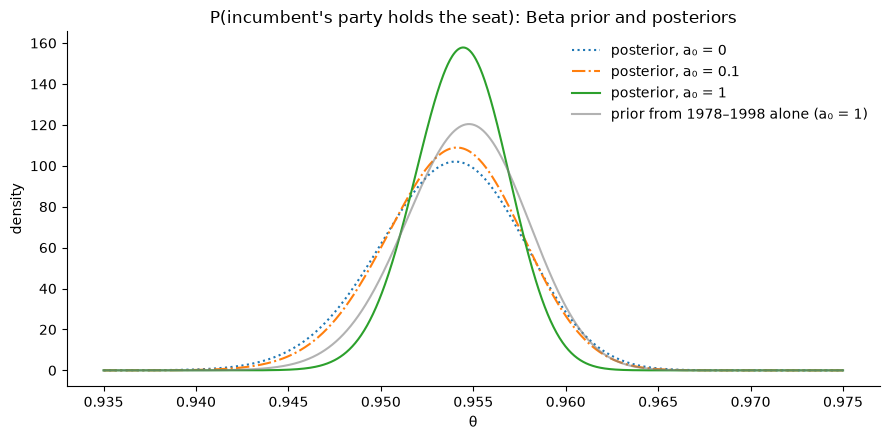

,"prior Beta(β_H, β_T)",posterior mean,95% credible interval
a₀ = 0,"Beta(1, 1)",0.954,0.946 – 0.961
a₀ = 0.1,"Beta(377, 19)",0.954,0.946 – 0.961
a₀ = 1,"Beta(3758, 179)",0.954,0.949 – 0.959


In [12]:
from scipy.stats import beta as beta_dist

def holds(data):
    inc = data[data["incumbent"] != 0]
    held = ((inc["incumbent"] == 1) & (inc["dem_win"] == 1)) | ((inc["incumbent"] == -1) & (inc["dem_win"] == 0))
    return int(held.sum()), int((~held).sum())

hist_H, hist_T = holds(years(df, PRIOR_YEARS))
data_H, data_T = holds(years(df, UPDATE_YEARS))
print(f"1978–1998 (prior):  {hist_H:,} holds, {hist_T} losses  -> rate {hist_H / (hist_H + hist_T):.3f}")
print(f"2000–2014 (data):   {data_H:,} holds, {data_T} losses  -> rate {data_H / (data_H + data_T):.3f}")

theta = np.linspace(0.935, 0.975, 1000)
fig, ax = plt.subplots()
rows = {}
for a0, style in [(0.0, ":"), (0.1, "-."), (1.0, "-")]:
    b_H, b_T = 1 + a0 * hist_H, 1 + a0 * hist_T                 # Beta prior: pseudo-counts from history
    post = beta_dist(data_H + b_H, data_T + b_T)                 # conjugate update
    ax.plot(theta, post.pdf(theta), linestyle=style, label=f"posterior, a₀ = {a0:g}")
    rows[f"a₀ = {a0:g}"] = {"prior Beta(β_H, β_T)": f"Beta({b_H:.0f}, {b_T:.0f})",
                            "posterior mean": post.mean(),
                            "95% credible interval": f"{post.ppf(0.025):.3f} – {post.ppf(0.975):.3f}"}
ax.plot(theta, beta_dist(1 + hist_H, 1 + hist_T).pdf(theta), color="gray", alpha=0.6,
        label="prior from 1978–1998 alone (a₀ = 1)")
ax.set(title="P(incumbent's party holds the seat): Beta prior and posteriors",
       xlabel="θ", ylabel="density")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGS / "beta_bernoulli_incumbency.png", dpi=150)
plt.show()

pd.DataFrame(rows).T

The two eras agree almost exactly: incumbents' parties held about 95.5% of seats in both. So every posterior lands in the same place, and the prior's only effect is on **certainty**. With a₀ = 1 the 3,935 historical races act as pseudo-counts, and the posterior is noticeably narrower than with the recent data alone.

This is the ideal case for a historical prior: when the past and the present agree, borrowing the past costs nothing and buys precision. The classifiers below test whether that still holds when the eras disagree on some quantities.

### 4.4 Naive Bayes with a historical prior

The Bayes classifier from Lectures 13–14 predicts the class with the highest posterior probability,

P(Y = y | x) ∝ P(Y = y) · P(x | Y = y),

and the **naive** assumption factors the likelihood into one term per feature, P(x | Y) = ∏ⱼ P(xⱼ | Y). Here Y is whether the Democrat wins, and each feature gets the kind of model the lectures used for it:

| Feature | Type | Model for P(xⱼ \| Y) |
|---|---|---|
| `margin_lag1`, `margin_lag2` | continuous | **Gaussian Naive Bayes**: a mean and variance per class, with variance smoothing ε |
| `incumbent` (−1, 0, +1) | categorical | **counts with Laplace smoothing** |
| national context (midterm or not × president's party, 4 values) | categorical | counts with Laplace smoothing |
| `redistrict_year`, `contested_lag1`, `has_lag2` | categorical | counts with Laplace smoothing |

The three national features (`midterm`, `pres_party`, `midterm_x_pres`) are combined into one four-valued *context* variable. That's the same information, but the interaction term is redundant once the two parts are known, and giving it to Naive Bayes separately would count the same evidence twice.

**Where the historical prior comes in.** Lecture 14 showed that Laplace smoothing *is* a prior: MAP estimation for Naive Bayes adds pseudo-counts *a* to every count, corresponding to a Dirichlet prior (the multi-valued version of the Beta). Instead of a uniform pseudo-count of 1, the older elections supply the pseudo-counts, scaled by a₀:

P(xⱼ = v | Y = y) = [Count₂₀₀₀₋₂₀₁₄(xⱼ = v, Y = y) + a₀·Count₁₉₇₈₋₁₉₉₈(xⱼ = v, Y = y) + 1] / [Count₂₀₀₀₋₂₀₁₄(Y = y) + a₀·Count₁₉₇₈₋₁₉₉₈(Y = y) + |Vⱼ|]

The class prior P(Y) is estimated the same way, and the Gaussian means and variances are computed with each 1978–1998 race weighted by a₀. As in Section 4.3, a₀ = 1 pools everything and a₀ = 0 leaves only the usual Laplace smoothing on 2000–2014.

Scores are computed in the **log domain** (a sum of log-probabilities) to avoid numerical underflow, then normalized back to a probability.

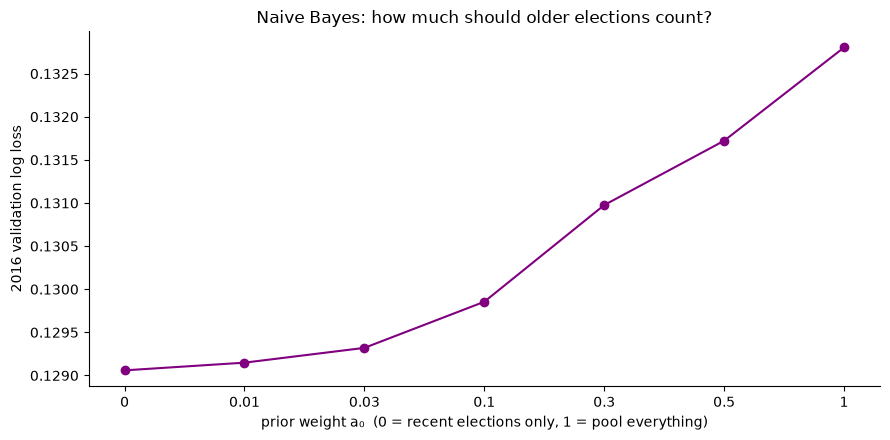

Selected a0 = 0


,validation log loss,validation Brier score,validation calibration error
a0,,,
0.000,0.129,0.029,0.028
0.010,0.129,0.029,0.028
0.030,0.129,0.029,0.029
0.100,0.130,0.029,0.029
0.300,0.131,0.029,0.030
0.500,0.132,0.029,0.031
1.000,0.133,0.029,0.031


In [13]:
from scipy.special import logsumexp

NB_CONT = ["margin_lag1", "margin_lag2"]
NB_CAT = {"incumbent": [-1, 0, 1],
          "context": ["0_-1", "0_1", "1_-1", "1_1"],      # "<midterm>_<president's party>"
          "redistrict_year": [0, 1], "contested_lag1": [0, 1], "has_lag2": [0, 1]}
NB_EPS = 1e-3                                             # variance smoothing

def nb_frame(data):
    out = data.copy()
    out["context"] = out["midterm"].astype(int).astype(str) + "_" + out["pres_party"].astype(int).astype(str)
    return out

def fit_naive_bayes(hist, recent, a0):
    # Count-based MAP estimates: recent counts + a0 * historical pseudo-counts + Laplace smoothing.
    data = pd.concat([hist, recent])
    w = np.concatenate([np.full(len(hist), a0), np.ones(len(recent))])
    y = data["dem_win"].to_numpy()
    model = {"log_prior": np.log([(w[y == c].sum() + 1) / (w.sum() + 2) for c in (0, 1)]),
             "cat": {}, "gauss": {}}
    for f, values in NB_CAT.items():
        x = data[f].to_numpy()
        model["cat"][f] = [{v: np.log((w[(y == c) & (x == v)].sum() + 1) / (w[y == c].sum() + len(values)))
                            for v in values} for c in (0, 1)]
    for f in NB_CONT:
        x = data[f].to_numpy(dtype=float)
        stats = []
        for c in (0, 1):
            mu = np.average(x[y == c], weights=w[y == c])
            var = np.average((x[y == c] - mu) ** 2, weights=w[y == c]) + NB_EPS
            stats.append((mu, var))
        model["gauss"][f] = stats
    return model

def predict_naive_bayes(model, data):
    scores = np.zeros((len(data), 2))
    for c in (0, 1):
        s = np.full(len(data), model["log_prior"][c])
        for f in NB_CAT:
            s += data[f].map(model["cat"][f][c]).to_numpy()
        for f in NB_CONT:
            mu, var = model["gauss"][f][c]
            x = data[f].to_numpy(dtype=float)
            s += -0.5 * np.log(2 * np.pi * var) - (x - mu) ** 2 / (2 * var)
        scores[:, c] = s
    return np.exp(scores[:, 1] - logsumexp(scores, axis=1))   # P(Democrat wins | x)

nb_df = nb_frame(df)
nb_prior, nb_update, nb_val = years(nb_df, PRIOR_YEARS), years(nb_df, UPDATE_YEARS), years(nb_df, VAL_YEAR)

A0_GRID = [0.0, 0.01, 0.03, 0.1, 0.3, 0.5, 1.0]
nb_models, rows = {}, []
for a0 in A0_GRID:
    nb_models[a0] = fit_naive_bayes(nb_prior, nb_update, a0)
    p_val = predict_naive_bayes(nb_models[a0], nb_val)
    rows.append({"a0": a0, "validation log loss": log_loss(y_val, p_val),
                 "validation Brier score": brier_score_loss(y_val, p_val),
                 "validation calibration error": expected_calibration_error(y_val, p_val)})
a0_nb = pd.DataFrame(rows).set_index("a0")
best_a0_nb = a0_nb["validation log loss"].idxmin()

fig, ax = plt.subplots()
ax.plot(range(len(A0_GRID)), a0_nb["validation log loss"], marker="o", color="purple")
ax.set_xticks(range(len(A0_GRID)), [f"{a:g}" for a in A0_GRID])
ax.set(title="Naive Bayes: how much should older elections count?",
       xlabel="prior weight a₀  (0 = recent elections only, 1 = pool everything)",
       ylabel="2016 validation log loss")
fig.tight_layout(); fig.savefig(FIGS / "naive_bayes_prior_weight.png", dpi=150)
plt.show()

print(f"Selected a0 = {best_a0_nb:g}")
a0_nb

On 2016, the recent-only version (a₀ = 0) is best, but only barely: log loss ranges from 0.129 to 0.133 across all prior weights. Naive Bayes also has the **best calibration error of any model on 2016** (about 0.03).

**What the model learned.** For the categorical features, the table shows P(feature value | Democrat wins) and P(feature value | Republican wins) under the selected prior weight. The ratio between the two columns is how strongly each value pushes the prediction one way or the other.

In [14]:
m = nb_models[best_a0_nb]
nb_table = pd.DataFrame(
    [(f, v, np.exp(m["cat"][f][1][v]), np.exp(m["cat"][f][0][v])) for f in NB_CAT for v in NB_CAT[f]],
    columns=["feature", "value", "P(value | D wins)", "P(value | R wins)"]).set_index(["feature", "value"])
nb_table["ratio (D / R)"] = nb_table["P(value | D wins)"] / nb_table["P(value | R wins)"]
gauss = pd.DataFrame({f: {"mean | D wins": m["gauss"][f][1][0], "SD | D wins": np.sqrt(m["gauss"][f][1][1]),
                          "mean | R wins": m["gauss"][f][0][0], "SD | R wins": np.sqrt(m["gauss"][f][0][1])}
                      for f in NB_CONT}).T
display(gauss)
nb_table

,mean | D wins,SD | D wins,mean | R wins,SD | R wins
margin_lag1,0.414,0.347,-0.323,0.342
margin_lag2,0.367,0.383,-0.280,0.376


P(value | D wins)  P(value | R wins)  ratio (D / R)
feature         value                                                     
incumbent       -1                 0.034              0.771          0.044
                0                  0.150              0.186          0.810
                1                  0.816              0.043         18.814
context         0_-1               0.273              0.231          1.182
                0_1                0.241              0.254          0.948
                1_-1               0.258              0.239          1.083
                1_1                0.227              0.276          0.823
redistrict_year 0                  0.765              0.745          1.026
                1                  0.235              0.255          0.923
contested_lag1  0                  0.144              0.140          1.026
                1                  0.856              0.860          0.996
has_lag2        0                  0.007              0.008          0.774
                1                  0.993              0.992          1.002

**Incumbency dominates.** A Democratic incumbent is about 19 times more likely in races Democrats win than in races they lose, and the Gaussian means for the previous margins are far apart (about +0.41 vs. −0.32).

**The national context barely moves the prediction.** Its ratios are all between about 0.8 and 1.2. In Naive Bayes, the national context only enters through how often each context appears among Democratic and Republican wins, and across many elections those frequencies differ only slightly. So this model largely ignores national swings, which turns out to cut both ways in Section 7.

**The naive assumption is clearly violated.** `margin_lag1`, `margin_lag2` and `incumbent` all measure much the same thing (how Democratic the district is), but the model multiplies their likelihoods as if each were independent evidence. Lecture 14 noted that Naive Bayes can still rank well when this happens, but its **probabilities become overconfident**, because the same evidence is counted several times.

### 4.5 Bayesian logistic regression with a historical prior (extension)

Naive Bayes is the Bayesian classifier from the lectures, but its naive assumption is a poor fit for this data: the previous two margins and incumbency are strongly related, so treating them as independent counts the same evidence more than once. This section applies the same Bayesian ideas (prior × likelihood, MAP estimation, a prior built from history) to the model from Section 4.1, which doesn't need that assumption. It goes beyond the specific models covered in lecture, so it is included as an extension.

The model is P(Democrat wins) = σ(x̃ᵀw), but instead of a single best weight vector it produces a **posterior distribution** over w, in two steps:

1. **Learn from history.** Fit the model to the 1978–1998 elections alone. Starting from a flat prior, the posterior after these elections is approximately Gaussian (the *Laplace approximation*): centered at the maximum-likelihood weights **w_hist**, with covariance **Σ_hist** equal to the inverse of the Hessian of the negative log-likelihood at that point.
2. **Use that as the prior for 2000–2014.** The prior is **w ~ N(w_hist, Σ_hist / a₀)**. The posterior after observing 2000–2014 is found the same way: its most likely value (the MAP estimate) minimizes

   cross-entropy on 2000–2014 + ½ a₀ (w − w_hist)ᵀ Σ_hist⁻¹ (w − w_hist),

   and its covariance is the inverse Hessian at that point.

**The prior weight a₀** controls how much one older election counts relative to one recent election (this construction is known as a *power prior*):

| a₀ | Meaning |
|---|---|
| 1 | Older elections count fully, which is equivalent to pooling all of 1978–2014 |
| 0 | The prior vanishes, so only 2000–2014 is used |
| between | Older elections count partially |

This is the same a₀ as in Sections 4.3–4.4, applied to the model's weights instead of to counts.

**Connection to Lectures 5 and 13–14.** As in the thumbtack example, a uniform prior would reduce this to maximum likelihood (the ordinary logistic regression fit), and the MAP estimate with a prior is the most probable weight vector after seeing the data. The penalty term is L2 regularization with two differences: it pulls the weights toward the *historical estimate* rather than toward zero, and its strength differs by direction, being strongest where the old elections pinned the weights down most precisely.

**Predictions** average over the posterior rather than plugging in one weight vector. For a race with features x̃, the score x̃ᵀw has posterior mean μ and variance s², and the predicted probability uses the standard approximation σ(μ / √(1 + πs²/8)). This pulls predictions slightly toward 50% when the weights are uncertain.

The fitting is done directly in NumPy with Newton's method: gradient descent (Lecture 4) that also uses the curvature of the loss, which converges in a handful of steps for a problem this size.

In [15]:
from scipy.special import expit
from scipy.stats import norm

# One scaler for every Bayesian model, fit on the 1978–2014 training features, plus an intercept column.
bayes_scaler = StandardScaler().fit(train[FEATURES].to_numpy(dtype=float))
PARAMS = ["intercept"] + FEATURES

def design(data):
    Z = bayes_scaler.transform(data[FEATURES].to_numpy(dtype=float))
    return np.column_stack([np.ones(len(Z)), Z])

def fit_bayes_logistic(X, y, prior_mean, prior_prec, iters=100, tol=1e-10):
    # MAP estimate by Newton's method; returns the posterior mean and covariance (Laplace approximation).
    w = prior_mean.copy()
    for _ in range(iters):
        p = expit(X @ w)
        grad = X.T @ (p - y) + prior_prec @ (w - prior_mean)
        hess = X.T @ (X * (p * (1 - p))[:, None]) + prior_prec
        step = np.linalg.solve(hess, grad)
        w -= step
        if np.abs(step).max() < tol:
            break
    p = expit(X @ w)
    hess = X.T @ (X * (p * (1 - p))[:, None]) + prior_prec
    return w, np.linalg.inv(hess)

def predict_bayes_logistic(X, w, cov):
    mu = X @ w
    s2 = np.einsum("ij,jk,ik->i", X, cov, X)          # posterior variance of each race's score
    return expit(mu / np.sqrt(1 + np.pi * s2 / 8))

FLAT = 1e-6 * np.eye(len(PARAMS))                     # an (almost) flat prior
prior_df, update_df = years(df, PRIOR_YEARS), years(df, UPDATE_YEARS)
Xb_prior, yb_prior = design(prior_df), prior_df["dem_win"].to_numpy()
Xb_upd, yb_upd = design(update_df), update_df["dem_win"].to_numpy()
Xb_val = design(val)

# Step 1: what the 1978–1998 elections say about the weights
w_hist, cov_hist = fit_bayes_logistic(Xb_prior, yb_prior, np.zeros(len(PARAMS)), FLAT)
prec_hist = np.linalg.inv(cov_hist)

pd.DataFrame({"w_hist (mean)": w_hist, "posterior SD": np.sqrt(np.diag(cov_hist))}, index=PARAMS)

,w_hist (mean),posterior SD
intercept,0.197,0.063
margin_lag1,1.149,0.130
margin_lag2,0.225,0.097
has_lag2,-0.072,0.052
contested_lag1,0.145,0.100
incumbent,2.090,0.083
midterm,0.063,0.060
pres_party,-0.088,0.093
midterm_x_pres,-0.289,0.090
redistrict_year,0.128,0.064


**Step 1 result.** These are the weights implied by 1978–1998 alone, with their uncertainty. They become the prior for the next step.

**Step 2: update with 2000–2014 at a range of prior weights**, and score each posterior on 2016.

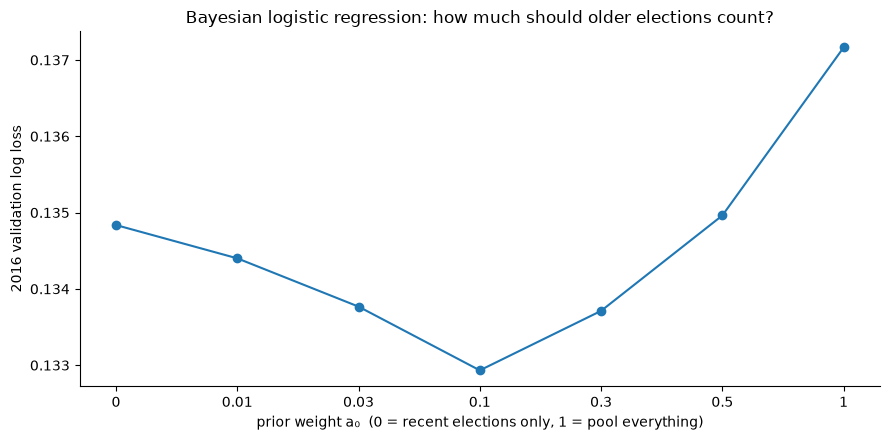

Selected a0 = 0.1


,validation log loss,validation Brier score,validation calibration error
a0,,,
0.000,0.135,0.033,0.052
0.010,0.134,0.032,0.053
0.030,0.134,0.032,0.049
0.100,0.133,0.031,0.050
0.300,0.134,0.031,0.044
0.500,0.135,0.031,0.046
1.000,0.137,0.032,0.043


In [16]:
bayes_clf = {}                                        # a0 -> (posterior mean, posterior covariance)
rows = []
for a0 in A0_GRID:
    prior_prec = a0 * prec_hist if a0 > 0 else FLAT
    w_post, cov_post = fit_bayes_logistic(Xb_upd, yb_upd, w_hist if a0 > 0 else np.zeros(len(PARAMS)), prior_prec)
    bayes_clf[a0] = (w_post, cov_post)
    p_val = predict_bayes_logistic(Xb_val, w_post, cov_post)
    rows.append({"a0": a0,
                 "validation log loss": log_loss(y_val, p_val),
                 "validation Brier score": brier_score_loss(y_val, p_val),
                 "validation calibration error": expected_calibration_error(y_val, p_val)})
a0_clf = pd.DataFrame(rows).set_index("a0")
best_a0_clf = a0_clf["validation log loss"].idxmin()

fig, ax = plt.subplots()
ax.plot(range(len(A0_GRID)), a0_clf["validation log loss"], marker="o")
ax.set_xticks(range(len(A0_GRID)), [f"{a:g}" for a in A0_GRID])
ax.set(title="Bayesian logistic regression: how much should older elections count?",
       xlabel="prior weight a₀  (0 = recent elections only, 1 = pool everything)",
       ylabel="2016 validation log loss")
fig.tight_layout(); fig.savefig(FIGS / "bayes_clf_prior_weight.png", dpi=150)
plt.show()

print(f"Selected a0 = {best_a0_clf:g}")
a0_clf

The validation curve is very flat: log loss ranges only from 0.133 to 0.137 across all prior weights. The best value, a₀ = 0.1, means each 1978–1998 election counts about a tenth as much as a 2000–2014 election. So on 2016, down-weighting the older elections helps slightly, which is consistent with the exploratory finding that recent results are more predictable. But the differences are small, and 2016 is a single election. Section 7 tests whether the choice holds up.

**Sanity check.** With a₀ = 1, the posterior should match a model fit to all of 1978–2014 at once, because the prior then carries the full information from the older elections. Comparing the two directly:

In [17]:
w_pooled, _ = fit_bayes_logistic(design(train), train["dem_win"].to_numpy(), np.zeros(len(PARAMS)), FLAT)
check = pd.DataFrame({"a0 = 1 (prior + update)": bayes_clf[1.0][0], "fit to all 1978–2014": w_pooled}, index=PARAMS)
print(f"Largest difference between the two: {np.abs(check.iloc[:, 0] - check.iloc[:, 1]).max():.3f}")
check

Largest difference between the two: 0.015


,a0 = 1 (prior + update),fit to all 1978–2014
intercept,0.150,0.151
margin_lag1,1.234,1.248
margin_lag2,0.269,0.268
has_lag2,-0.150,-0.149
contested_lag1,0.269,0.279
incumbent,2.042,2.054
midterm,-0.145,-0.147
pres_party,-0.119,-0.119
midterm_x_pres,-0.446,-0.449
redistrict_year,-0.012,-0.015


**How the evidence changed the weights.** The plot shows each weight's 95% interval under the historical prior alone (1978–1998) and under the selected posterior (after adding 2000–2014). Where the intervals don't overlap, the newer elections disagree with the older ones.

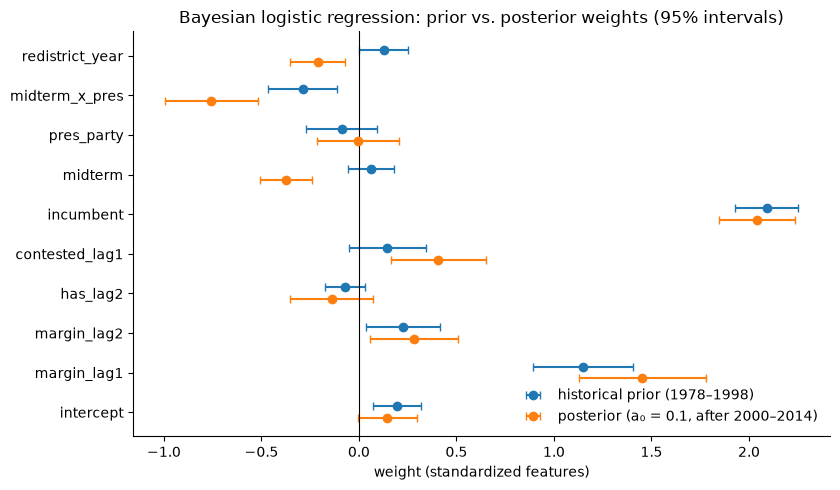

,prior mean (1978–1998),prior SD,posterior mean,posterior SD
intercept,0.197,0.063,0.145,0.077
margin_lag1,1.149,0.130,1.453,0.165
margin_lag2,0.225,0.097,0.282,0.115
has_lag2,-0.072,0.052,-0.139,0.109
contested_lag1,0.145,0.100,0.408,0.124
incumbent,2.090,0.083,2.043,0.100
midterm,0.063,0.060,-0.374,0.067
pres_party,-0.088,0.093,-0.005,0.106
midterm_x_pres,-0.289,0.090,-0.756,0.122
redistrict_year,0.128,0.064,-0.212,0.072


In [18]:
w_best, cov_best = bayes_clf[best_a0_clf]
compare = pd.DataFrame({
    "prior mean (1978–1998)": w_hist, "prior SD": np.sqrt(np.diag(cov_hist)),
    "posterior mean": w_best,        "posterior SD": np.sqrt(np.diag(cov_best)),
}, index=PARAMS)

fig, ax = plt.subplots(figsize=(8.5, 5))
ypos = np.arange(len(PARAMS))
ax.errorbar(compare["prior mean (1978–1998)"], ypos + 0.15, xerr=1.96 * compare["prior SD"],
            fmt="o", capsize=3, label="historical prior (1978–1998)")
ax.errorbar(compare["posterior mean"], ypos - 0.15, xerr=1.96 * compare["posterior SD"],
            fmt="o", capsize=3, label=f"posterior (a₀ = {best_a0_clf:g}, after 2000–2014)")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(ypos, PARAMS)
ax.set(title="Bayesian logistic regression: prior vs. posterior weights (95% intervals)",
       xlabel="weight (standardized features)")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(FIGS / "bayes_clf_prior_vs_posterior.png", dpi=150)
plt.show()

compare

**District-level weights are stable across eras.** The incumbency weight is nearly identical in both periods. The previous margin matters somewhat more in 2000–2014, consistent with results becoming more predictable.

**National-level weights moved the most.** The midterm-penalty term `midterm_x_pres` and the `midterm` weight became much more negative, and `redistrict_year` flipped sign. According to these intervals, the 2000–2014 elections disagree clearly with 1978–1998 on all three.

**An important caution about those intervals.** The model treats every race as an independent observation, but the national features take a single value for an entire election. In 2000–2014, the midterm effects are really estimated from just four midterms (2002, 2006, 2010, 2014), and the redistricting effect from just two elections (2002 and 2012). The true uncertainty about these weights is much larger than the intervals suggest, because a handful of elections is a small sample no matter how many races each contains. This turns out to matter a great deal in Section 7.

### 4.6 Validation comparison

The table compares all four classifiers on 2016. The reliability diagram (calibration plot) groups races by predicted probability and plots the share Democrats actually won: a perfectly calibrated model lies on the diagonal.

2016 has 32 competitive races, so one race moves competitive accuracy by 3.1%.


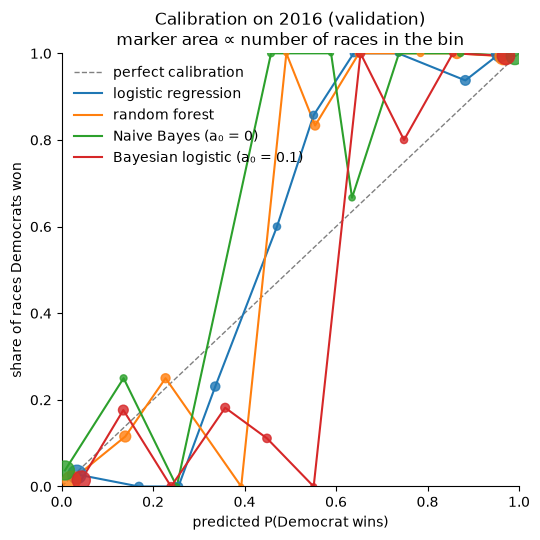

,log loss,Brier score,ROC AUC,calibration error,accuracy,accuracy (competitive),macro F1,precision (D win),recall (D win)
baseline (same party wins),NaN,NaN,NaN,NaN,0.972,0.750,0.972,0.984,0.954
logistic regression,0.137,0.032,0.988,0.042,0.968,0.688,0.967,0.989,0.938
random forest,0.124,0.030,0.990,0.036,0.970,0.719,0.970,0.984,0.948
Naive Bayes (a₀ = 0),0.129,0.029,0.989,0.028,0.963,0.688,0.963,0.989,0.928
Bayesian logistic (a₀ = 0.1),0.133,0.031,0.988,0.050,0.970,0.750,0.970,0.979,0.954


In [19]:
val_preds = {"logistic regression": lr.predict_proba(X_val)[:, 1],
             "random forest":       rf.predict_proba(X_val)[:, 1],
             f"Naive Bayes (a₀ = {best_a0_nb:g})": predict_naive_bayes(nb_models[best_a0_nb], nb_val),
             f"Bayesian logistic (a₀ = {best_a0_clf:g})": predict_bayes_logistic(Xb_val, *bayes_clf[best_a0_clf])}

clf_val = pd.DataFrame({"baseline (same party wins)": clf_metrics(val, yhat=baseline_labels(val)),
                        **{name: clf_metrics(val, p) for name, p in val_preds.items()}}).T
clf_val.to_csv(RESULTS / "validation_classification.csv")
print(f"2016 has {val['competitive'].sum()} competitive races, so one race moves competitive accuracy by "
      f"{1 / val['competitive'].sum():.1%}.")

def reliability(ax, y, p, label, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1)
    pts = [(p[idx == b].mean(), y[idx == b].mean(), (idx == b).sum()) for b in range(bins) if (idx == b).any()]
    xs, ys, ns = map(np.array, zip(*pts))
    line, = ax.plot(xs, ys, label=label)
    ax.scatter(xs, ys, s=12 * np.sqrt(ns), color=line.get_color(), alpha=0.8, zorder=3)
    return ns

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1, label="perfect calibration")
for name, p in val_preds.items():
    reliability(ax, y_val, p, name)
ax.set(title="Calibration on 2016 (validation)\nmarker area ∝ number of races in the bin", xlabel="predicted P(Democrat wins)",
       ylabel="share of races Democrats won", xlim=(0, 1), ylim=(0, 1))
ax.legend(frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(FIGS / "calibration_validation.png", dpi=150)
plt.show()

clf_val

**Accuracy:** no model beats the baseline on 2016. In a status-quo year, "same party wins again" is very hard to beat on labels alone, and on 32 competitive races the gaps amount to one or two races.

**Probabilities:** this is where the models add value. All four rank races almost perfectly (ROC AUC around 0.99). The random forest has the best log loss, and Naive Bayes has the best Brier score and calibration error. The two logistic models trail slightly.

**Calibration:** the logistic models' reliability curves are steeper than the diagonal. Races given a 60–70% chance went to Democrats almost every time, and races given 20–30% rarely did, so **they are underconfident on 2016.** This connects to the exploratory analysis: results have become more predictable since the 1980s, and models trained on all of 1978–2014 inherit the noisier older elections' uncertainty. Naive Bayes's double-counting pushes its probabilities toward 0 and 1, which happens to offset this on 2016. The middle bins contain few races, so the exact shapes are noisy.

## 5. Regression: by how much?

The regression models predict the two-party margin itself. Following the exploratory analysis (`01_explore.ipynb`, Section 2), they are trained and evaluated on **contested races only**: an uncontested race's margin of exactly ±1 says nothing about how competitive the district is. Section 5.2 tests what happens if those races are left in.

Each model is scored on **RMSE** (root mean squared error, in margin units, so 0.05 = 5 points), **MAE** (mean absolute error), and the **winner accuracy** implied by the sign of the predicted margin, overall and on competitive races.

In [20]:
reg_df = df[df["contested"]]
reg_train, reg_val = years(reg_df, TRAIN_YEARS), years(reg_df, VAL_YEAR)
Xr_tr, yr_tr = Xy(reg_train, "margin")
Xr_val, yr_val = Xy(reg_val, "margin")

def reg_metrics(data, pred):
    y = data["margin"].to_numpy()
    comp = data["competitive"].to_numpy()
    won = data["dem_win"].to_numpy()
    called = (pred > 0).astype(int)
    return {"RMSE": np.sqrt(mean_squared_error(y, pred)),
            "MAE": mean_absolute_error(y, pred),
            "winner accuracy": accuracy_score(won, called),
            "winner accuracy (competitive)": accuracy_score(won[comp], called[comp])}

print(f"train: {len(reg_train):,} contested races   validation: {len(reg_val):,} contested races")

train: 7,031 contested races   validation: 371 contested races


### 5.1 Least squares vs. least absolute deviations

- **Least squares** minimizes the squared residuals, which has a closed-form solution (the normal equations).
- **LAD** minimizes the absolute residuals (Lecture 4). It is less sensitive to large residuals, at the cost of no closed form. scikit-learn fits it as median (50th percentile) quantile regression, with `alpha=0` meaning no regularization.

Neither model has hyperparameters here, so the 2016 results are a direct comparison.

In [21]:
ols = make_pipeline(StandardScaler(), LinearRegression()).fit(Xr_tr, yr_tr)
lad = make_pipeline(StandardScaler(), QuantileRegressor(quantile=0.5, alpha=0.0, solver="highs")).fit(Xr_tr, yr_tr)

reg_val_table = pd.DataFrame({
    "baseline (same margin as last time)": reg_metrics(reg_val, reg_val["margin_lag1"].to_numpy()),
    "least squares": reg_metrics(reg_val, ols.predict(Xr_val)),
    "LAD":           reg_metrics(reg_val, lad.predict(Xr_val)),
}).T
reg_val_table.to_csv(RESULTS / "validation_regression.csv")

reg_coefs = pd.DataFrame({"least squares": ols[-1].coef_, "LAD": lad[-1].coef_}, index=FEATURES)
display(reg_val_table)
reg_coefs

,RMSE,MAE,winner accuracy,winner accuracy (competitive)
baseline (same margin as last time),0.252,0.150,0.968,0.750
least squares,0.141,0.107,0.965,0.750
LAD,0.139,0.105,0.968,0.750


,least squares,LAD
margin_lag1,0.134,0.156
margin_lag2,0.051,0.048
has_lag2,-0.007,-0.005
contested_lag1,0.006,0.000
incumbent,0.157,0.147
midterm,-0.012,-0.013
pres_party,0.004,0.006
midterm_x_pres,-0.038,-0.045
redistrict_year,-0.002,-0.003


Both models cut the baseline's error substantially (RMSE from 0.25 to about 0.14). The baseline repeats last cycle's margin exactly, including ±1 for districts that were uncontested last time, while the models shrink extreme past margins toward the center and adjust for incumbency and the national environment.

Least squares and LAD are nearly identical on contested races, with LAD marginally better. That's expected: once uncontested races are removed there are few extreme residuals left for the two losses to treat differently. The coefficients tell the same story as the classifier: the previous margin and incumbency dominate, and the midterm-penalty term is negative.

The winner accuracy implied by the predicted margins matches the baseline. In 2016 the margin models mostly add information about *how close* a race will be, not *who* wins.

### 5.2 Outlier experiment: what if uncontested races are left in?

Lecture 4 showed that squared error lets a few large residuals pull the fitted line toward them, while absolute error resists. Uncontested races are a natural real-world version of this: their margins of exactly ±1 sit far from what the features predict. Here both models are retrained **with** the uncontested races included, then evaluated on the same contested 2016 races as before.

Training races: 7,031 contested only vs. 8,190 including uncontested (14.2% are uncontested)


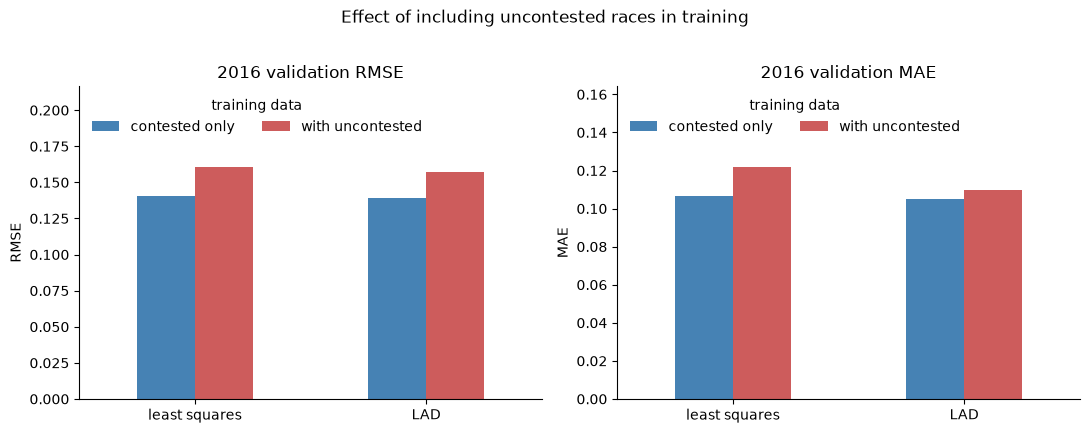

RMSE   MAE  winner accuracy  \
least squares contested only   0.141 0.107            0.965   
              with uncontested 0.160 0.122            0.968   
LAD           contested only   0.139 0.105            0.968   
              with uncontested 0.157 0.110            0.968   

                                winner accuracy (competitive)  
least squares contested only                            0.750  
              with uncontested                          0.750  
LAD           contested only                            0.750  
              with uncontested                          0.750

In [22]:
all_train = years(df, TRAIN_YEARS)
Xa_tr, ya_tr = Xy(all_train, "margin")
print(f"Training races: {len(reg_train):,} contested only vs. {len(all_train):,} including uncontested "
      f"({1 - len(reg_train) / len(all_train):.1%} are uncontested)")

ols_all = make_pipeline(StandardScaler(), LinearRegression()).fit(Xa_tr, ya_tr)
lad_all = make_pipeline(StandardScaler(), QuantileRegressor(quantile=0.5, alpha=0.0, solver="highs")).fit(Xa_tr, ya_tr)

outlier_table = pd.DataFrame({
    ("least squares", "contested only"):     reg_metrics(reg_val, ols.predict(Xr_val)),
    ("least squares", "with uncontested"):   reg_metrics(reg_val, ols_all.predict(Xr_val)),
    ("LAD", "contested only"):               reg_metrics(reg_val, lad.predict(Xr_val)),
    ("LAD", "with uncontested"):             reg_metrics(reg_val, lad_all.predict(Xr_val)),
}).T
outlier_table.to_csv(RESULTS / "validation_outlier_experiment.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, metric in zip(axes, ["RMSE", "MAE"]):
    vals = outlier_table[metric].unstack().reindex(["least squares", "LAD"])
    vals.plot.bar(ax=ax, rot=0, color=["steelblue", "indianred"])
    ax.set(title=f"2016 validation {metric}", xlabel="", ylabel=metric, ylim=(0, vals.values.max() * 1.35))
    ax.legend(title="training data", frameon=False, loc="upper left", ncol=2)
fig.suptitle("Effect of including uncontested races in training", y=1.02)
fig.tight_layout(); fig.savefig(FIGS / "outlier_experiment.png", dpi=150, bbox_inches="tight")
plt.show()

outlier_table

Adding the uncontested races hurts both models on contested 2016 races, but **least squares is hurt much more on MAE**: its MAE rises from 0.107 to 0.122, while LAD's rises only from 0.105 to 0.110. With squared error, the ±1 margins pull the fitted relationship toward them, the same effect as the outlier example in Lecture 4. LAD largely resists. Both models' RMSE rise by similar amounts, because RMSE itself squares the errors and is dominated by the races each model gets most wrong.

This supports the decision to train the regression models on contested races only. It also suggests LAD is the safer choice whenever extreme values can't be filtered out cleanly.

### 5.3 Bayesian linear regression with a historical prior (extension)

The regression version follows the same two steps as Section 4.5, and it is the regression counterpart of the Beta–Bernoulli model in Section 4.3. There, a Beta prior is conjugate to the Bernoulli likelihood, so the posterior is again a Beta with the counts added. Here, a **Gaussian prior is conjugate to the Gaussian likelihood**, so the posterior is again Gaussian and every step has an exact closed form. With a uniform prior the posterior mode is exactly the least-squares fit, since least squares is maximum likelihood under Gaussian noise. Like Section 4.5, this goes beyond the specific models from lecture and is included as an extension.

**Model.** margin = x̃ᵀw + noise, with noise ~ N(0, σ²).

1. **Learn from history.** Least squares on the contested 1978–1998 races gives w_hist, with covariance Σ_hist = σ²_hist (XᵀX)⁻¹.
2. **Prior for 2000–2014:** w ~ N(w_hist, Σ_hist / a₀), with the same prior weight a₀ as before.
3. **Posterior after 2000–2014.** With prior precision P₀ = a₀ Σ_hist⁻¹:

   S_N = (P₀ + XᵀX / σ²)⁻¹ and m_N = S_N (P₀ w_hist + Xᵀy / σ²).

   This is the normal equations from Lecture 4 with the prior added in. With a₀ = 0 it reduces exactly to least squares on 2000–2014.
4. **Predictions are distributions.** For a race with features x̃, the predicted margin is N(x̃ᵀm_N, σ² + x̃ᵀS_N x̃). The first term is the race-to-race noise; the second is the remaining uncertainty about the weights. This gives a **90% credible interval** for every race.

**Where σ² comes from matters.** The exploratory analysis (`01_explore.ipynb`, Section 3) found that the spread of results around the trend has roughly halved since the 1980s. So the noise level is estimated from the recent 2000–2014 elections, not copied from the prior period. Below, the alternative (noise from 1978–1998) is also run, to show what that choice does to the intervals.

**Scoring.** Besides RMSE and MAE, each model is scored on:
- **interval coverage:** the share of actual margins inside the 90% intervals, which should be close to 90%;
- **mean negative log predictive density (NLPD):** how much probability the predicted distribution gave to what actually happened. Lower is better, and it rewards intervals that are both honest and narrow. The prior weight a₀ is tuned on this measure.

In [23]:
reg_prior, reg_update = years(reg_df, PRIOR_YEARS), years(reg_df, UPDATE_YEARS)
Xr_prior, yr_prior = design(reg_prior), reg_prior["margin"].to_numpy()
Xr_upd, yr_upd = design(reg_update), reg_update["margin"].to_numpy()
Xr_val_b = design(reg_val)

def ols_fit(X, y):
    w = np.linalg.solve(X.T @ X, X.T @ y)
    resid = y - X @ w
    sigma2 = resid @ resid / (len(y) - X.shape[1])
    return w, sigma2

def fit_bayes_linear(X, y, prior_mean, prior_prec, sigma2):
    S_N = np.linalg.inv(prior_prec + X.T @ X / sigma2)
    m_N = S_N @ (prior_prec @ prior_mean + X.T @ y / sigma2)
    return m_N, S_N

def predict_bayes_linear(X, m_N, S_N, sigma2):
    mean = X @ m_N
    sd = np.sqrt(sigma2 + np.einsum("ij,jk,ik->i", X, S_N, X))
    return mean, sd

def interval_metrics(y, mean, sd, level=0.90):
    z = norm.ppf(0.5 + level / 2)
    return {f"{level:.0%} interval coverage": np.mean(np.abs(y - mean) <= z * sd),
            f"{level:.0%} interval width": np.mean(2 * z * sd),
            "NLPD": -np.mean(norm.logpdf(y, mean, sd))}

# Step 1: history
w_hist_r, sigma2_hist = ols_fit(Xr_prior, yr_prior)
cov_hist_r = sigma2_hist * np.linalg.inv(Xr_prior.T @ Xr_prior)
prec_hist_r = np.linalg.inv(cov_hist_r)

# Noise level from the recent update period (see the exploratory analysis)
_, sigma2_recent = ols_fit(Xr_upd, yr_upd)
print(f"Noise SD estimated from 1978–1998: {np.sqrt(sigma2_hist):.3f}   "
      f"from 2000–2014: {np.sqrt(sigma2_recent):.3f}")

Noise SD estimated from 1978–1998: 0.184   from 2000–2014: 0.167


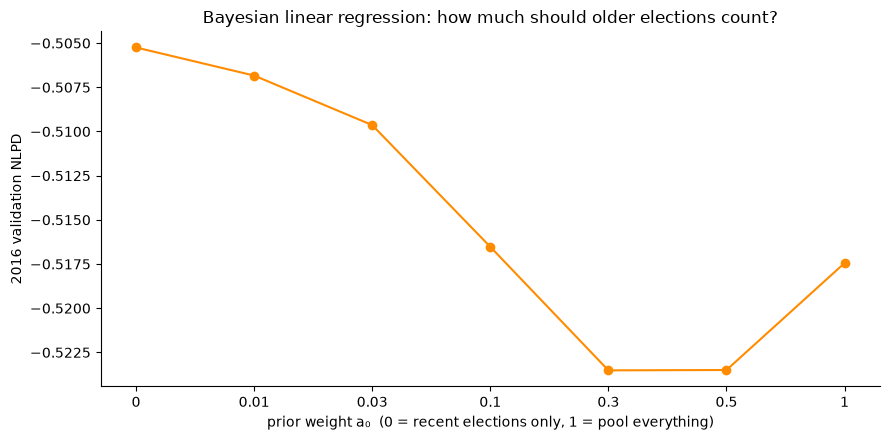

Selected a0 = 0.3


,validation RMSE,validation 90% interval coverage,validation 90% interval width,validation NLPD
a0,,,,
0.000,0.143,0.938,0.551,-0.505
0.010,0.142,0.938,0.551,-0.507
0.030,0.142,0.941,0.551,-0.510
0.100,0.140,0.943,0.551,-0.517
0.300,0.139,0.943,0.550,-0.524
0.500,0.139,0.935,0.550,-0.523
1.000,0.140,0.938,0.550,-0.517


In [24]:
bayes_reg = {}                                        # a0 -> (posterior mean, posterior covariance)
rows = []
for a0 in A0_GRID:
    m_N, S_N = fit_bayes_linear(Xr_upd, yr_upd, w_hist_r, a0 * prec_hist_r, sigma2_recent)
    bayes_reg[a0] = (m_N, S_N)
    mean, sd = predict_bayes_linear(Xr_val_b, m_N, S_N, sigma2_recent)
    rows.append({"a0": a0, "validation RMSE": np.sqrt(mean_squared_error(yr_val, mean)),
                 **{f"validation {k}": v for k, v in interval_metrics(yr_val, mean, sd).items()}})
a0_reg = pd.DataFrame(rows).set_index("a0")
best_a0_reg = a0_reg["validation NLPD"].idxmin()

fig, ax = plt.subplots()
ax.plot(range(len(A0_GRID)), a0_reg["validation NLPD"], marker="o", color="darkorange")
ax.set_xticks(range(len(A0_GRID)), [f"{a:g}" for a in A0_GRID])
ax.set(title="Bayesian linear regression: how much should older elections count?",
       xlabel="prior weight a₀  (0 = recent elections only, 1 = pool everything)",
       ylabel="2016 validation NLPD")
fig.tight_layout(); fig.savefig(FIGS / "bayes_reg_prior_weight.png", dpi=150)
plt.show()

print(f"Selected a0 = {best_a0_reg:g}")
a0_reg

The regression model shows the same pattern: a flat curve, with a moderate prior weight (a₀ = 0.3) slightly best on both NLPD and RMSE. Every variant's 90% intervals cover about 94% of 2016 margins, so they are a little too wide, but not badly so.

**Does the noise estimate matter?** The same posterior is used for the weights, but the predictive noise level comes from either the older or the recent elections:

In [25]:
m_best, S_best = bayes_reg[best_a0_reg]
noise_table = {}
for label, s2 in [("noise from 2000–2014 (used)", sigma2_recent), ("noise from 1978–1998", sigma2_hist)]:
    mean, sd = predict_bayes_linear(Xr_val_b, m_best, S_best, s2)
    noise_table[label] = {"RMSE": np.sqrt(mean_squared_error(yr_val, mean)), **interval_metrics(yr_val, mean, sd)}
pd.DataFrame(noise_table).T

,RMSE,90% interval coverage,90% interval width,NLPD
noise from 2000–2014 (used),0.139,0.943,0.550,-0.524
noise from 1978–1998,0.139,0.957,0.607,-0.487


Taking the noise level from the older elections (SD 0.184 instead of 0.167) makes the intervals about 10% wider. Coverage moves further above the nominal 90% (to 96%), and NLPD gets worse. This confirms the exploratory finding that older elections overstate today's uncertainty. The gap is smaller than in `01_explore.ipynb` because the regression data also includes races that were uncontested in the previous cycle, which are noisy in every era.

**Validation comparison of all three regression models:**

In [26]:
mean_val, sd_val = predict_bayes_linear(Xr_val_b, m_best, S_best, sigma2_recent)
reg_val_table.loc[f"Bayesian (a₀ = {best_a0_reg:g})"] = reg_metrics(reg_val, mean_val)
reg_val_table.to_csv(RESULTS / "validation_regression.csv")
reg_val_table

,RMSE,MAE,winner accuracy,winner accuracy (competitive)
baseline (same margin as last time),0.252,0.150,0.968,0.750
least squares,0.141,0.107,0.965,0.750
LAD,0.139,0.105,0.968,0.750
Bayesian (a₀ = 0.3),0.139,0.106,0.962,0.719


## 6. Research question: historical prior vs. pooled data

All three Bayesian models (Naive Bayes, Bayesian logistic regression, Bayesian linear regression) were fit across the same range of prior weights, which puts the three ways of using the training elections on a single scale:

- **pooled** (a₀ = 1): every 1978–2014 election counts equally, as in the standard models of Sections 4.1 and 5.1;
- **recent only** (a₀ = 0): only 2000–2014 counts;
- **historical prior** (0 < a₀ < 1): older elections count, but less than recent ones.

The plot puts the validation curves side by side. Each is measured relative to its own pooled model, so values below zero mean better calibrated than pooling.

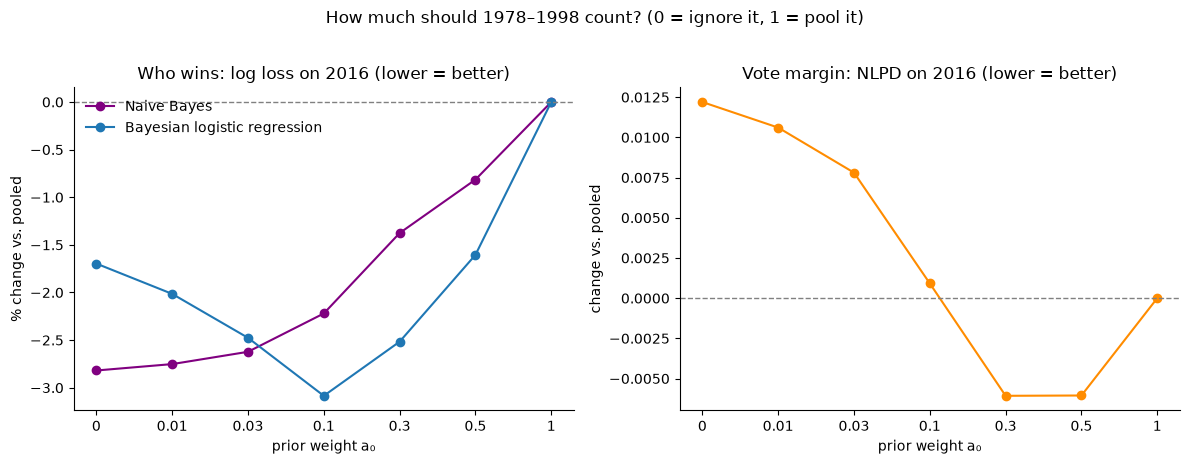

,Naive Bayes log loss,Bayesian logistic log loss,Bayesian logistic calibration error,regression NLPD,regression 90% coverage
a0,,,,,
0.000,0.129,0.135,0.052,-0.505,0.938
0.010,0.129,0.134,0.053,-0.507,0.938
0.030,0.129,0.134,0.049,-0.510,0.941
0.100,0.130,0.133,0.050,-0.517,0.943
0.300,0.131,0.134,0.044,-0.524,0.943
0.500,0.132,0.135,0.046,-0.523,0.935
1.000,0.133,0.137,0.043,-0.517,0.938


In [27]:
rel_nb  = a0_nb["validation log loss"] / a0_nb.loc[1.0, "validation log loss"] - 1
rel_clf = a0_clf["validation log loss"] / a0_clf.loc[1.0, "validation log loss"] - 1
rel_reg = a0_reg["validation NLPD"] - a0_reg.loc[1.0, "validation NLPD"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
xs = range(len(A0_GRID))
axes[0].plot(xs, rel_nb.values * 100, marker="o", color="purple", label="Naive Bayes")
axes[0].plot(xs, rel_clf.values * 100, marker="o", color="tab:blue", label="Bayesian logistic regression")
axes[0].legend(frameon=False)
axes[1].plot(xs, rel_reg.values, marker="o", color="darkorange")
for ax, title, ylabel in [(axes[0], "Who wins: log loss", "% change vs. pooled"),
                          (axes[1], "Vote margin: NLPD", "change vs. pooled")]:
    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_xticks(xs, [f"{a:g}" for a in A0_GRID])
    ax.set(title=f"{title} on 2016 (lower = better)", xlabel="prior weight a₀", ylabel=ylabel)
fig.suptitle("How much should 1978–1998 count? (0 = ignore it, 1 = pool it)", y=1.02)
fig.tight_layout(); fig.savefig(FIGS / "research_question_validation.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({
    "Naive Bayes log loss": a0_nb["validation log loss"],
    "Bayesian logistic log loss": a0_clf["validation log loss"],
    "Bayesian logistic calibration error": a0_clf["validation calibration error"],
    "regression NLPD": a0_reg["validation NLPD"],
    "regression 90% coverage": a0_reg["validation 90% interval coverage"],
}).rename_axis("a0")

On 2016, the three Bayesian models disagree mildly about the best prior weight. Naive Bayes prefers ignoring the older elections (a₀ = 0), Bayesian logistic regression prefers a small weight (a₀ = 0.1), and Bayesian linear regression a moderate one (a₀ = 0.3). All three curves are shallow: the best and worst prior weights differ by only a few percent.

**A caveat that matters for interpreting this.** 2016 was a presidential year with no redistricting. Every race had `midterm = 0`, `midterm_x_pres = 0` and `redistrict_year = 0`, and all shared the same `pres_party`. So the validation election cannot check the national-level effects at all, and those are exactly the effects that differ most between the two periods (Section 4.5). Tuning a₀ on 2016 really only tunes how the district-level effects are estimated. Whether the choices carry over to a midterm (2018) and to a midterm under brand-new district lines (2022) is the real test, and Section 7 runs it.

## 7. Final evaluation on the test and stress-test elections

Every model and hyperparameter is now fixed from the 2016 validation results:

| Model | Setting chosen on 2016 |
|---|---|
| Logistic regression | C from Section 4.1 |
| Random forest | depth and leaf size from Section 4.2 |
| Naive Bayes | a₀ from Section 4.4 |
| Bayesian logistic regression | a₀ from Section 4.5 |
| Bayesian linear regression | a₀ from Section 5.3 |

This section evaluates them, **once**, on the 2018 test election and the 2022 stress test. All models still train only on 1978–2014. For each Bayesian model, the pooled (a₀ = 1) and recent-only (a₀ = 0) variants are included alongside the selected one, to answer the research question on data that played no part in any choice.

In [28]:
print("Selected settings:", {"logistic C": round(best_C, 3), "forest depth": best_depth, "forest leaf": best_leaf,
                             "Naive Bayes a0": best_a0_nb, "Bayesian logistic a0": best_a0_clf,
                             "Bayesian regression a0": best_a0_reg})

def a0_label(a0, best, family="Bayesian"):
    name = {0.0: "recent only", 1.0: "pooled"}.get(a0, "historical prior")
    return f"{family}, {name} (a₀ = {a0:g})" + (" ← selected" if a0 == best else "")

NB_VARIANTS  = {a0: a0_label(a0, best_a0_nb, "Naive Bayes") for a0 in dict.fromkeys([best_a0_nb, 1.0, 0.0])}
CLF_VARIANTS = {a0: a0_label(a0, best_a0_clf, "Bayesian logistic") for a0 in dict.fromkeys([best_a0_clf, 1.0, 0.0])}
REG_VARIANTS = {a0: a0_label(a0, best_a0_reg) for a0 in dict.fromkeys([best_a0_reg, 1.0, 0.0])}

def clf_predictions(data):
    X, Xb = data[FEATURES].to_numpy(dtype=float), design(data)
    preds = {"logistic regression": lr.predict_proba(X)[:, 1],
             "random forest": rf.predict_proba(X)[:, 1]}
    for a0, label in NB_VARIANTS.items():
        preds[label] = predict_naive_bayes(nb_models[a0], nb_frame(data))
    for a0, label in CLF_VARIANTS.items():
        preds[label] = predict_bayes_logistic(Xb, *bayes_clf[a0])
    return preds

test, stress = years(df, TEST_YEAR), years(df, STRESS_YEAR)
final_preds = {TEST_YEAR: clf_predictions(test), STRESS_YEAR: clf_predictions(stress)}

clf_final = {}
for year, data in [(TEST_YEAR, test), (STRESS_YEAR, stress)]:
    table = pd.DataFrame({"baseline (same party wins)": clf_metrics(data, yhat=baseline_labels(data)),
                          **{name: clf_metrics(data, p) for name, p in final_preds[year].items()}}).T
    table.to_csv(RESULTS / f"final_classification_{year}.csv")
    clf_final[year] = table
    print(f"{year}: {len(data)} races, {data['competitive'].sum()} competitive")

print(f"\n=== {TEST_YEAR} test ===")
display(clf_final[TEST_YEAR])
print(f"\n=== {STRESS_YEAR} stress test (post-redistricting) ===")
clf_final[STRESS_YEAR]

Selected settings: {'logistic C': np.float64(0.316), 'forest depth': 8, 'forest leaf': 1, 'Naive Bayes a0': np.float64(0.0), 'Bayesian logistic a0': np.float64(0.1), 'Bayesian regression a0': np.float64(0.3)}
2018: 434 races, 89 competitive
2022: 426 races, 69 competitive

=== 2018 test ===


,log loss,Brier score,ROC AUC,calibration error,accuracy,accuracy (competitive),macro F1,precision (D win),recall (D win)
baseline (same party wins),NaN,NaN,NaN,NaN,0.882,0.573,0.882,0.974,0.803
logistic regression,0.313,0.094,0.949,0.074,0.887,0.584,0.887,0.970,0.816
random forest,0.278,0.089,0.950,0.047,0.887,0.596,0.887,0.984,0.803
"Naive Bayes, recent only (a₀ = 0) ← selected",0.607,0.116,0.944,0.117,0.878,0.562,0.878,0.984,0.786
"Naive Bayes, pooled (a₀ = 1)",0.599,0.116,0.944,0.117,0.878,0.562,0.878,0.984,0.786
"Bayesian logistic, historical prior (a₀ = 0.1) ← selected",0.306,0.093,0.949,0.067,0.887,0.573,0.887,0.960,0.825
"Bayesian logistic, pooled (a₀ = 1)",0.312,0.094,0.949,0.077,0.887,0.584,0.887,0.970,0.816
"Bayesian logistic, recent only (a₀ = 0)",0.303,0.092,0.949,0.066,0.880,0.551,0.880,0.933,0.838



=== 2022 stress test (post-redistricting) ===


,log loss,Brier score,ROC AUC,calibration error,accuracy,accuracy (competitive),macro F1,precision (D win),recall (D win)
baseline (same party wins),NaN,NaN,NaN,NaN,0.890,0.652,0.890,0.868,0.913
logistic regression,0.291,0.092,0.964,0.086,0.871,0.667,0.869,0.942,0.784
random forest,0.261,0.081,0.963,0.058,0.876,0.667,0.875,0.928,0.808
"Naive Bayes, recent only (a₀ = 0) ← selected",0.348,0.085,0.952,0.062,0.890,0.681,0.890,0.882,0.894
"Naive Bayes, pooled (a₀ = 1)",0.337,0.084,0.953,0.061,0.887,0.667,0.887,0.877,0.894
"Bayesian logistic, historical prior (a₀ = 0.1) ← selected",0.393,0.126,0.965,0.165,0.838,0.696,0.834,0.960,0.697
"Bayesian logistic, pooled (a₀ = 1)",0.292,0.092,0.964,0.089,0.869,0.667,0.867,0.942,0.779
"Bayesian logistic, recent only (a₀ = 0)",0.458,0.146,0.965,0.199,0.817,0.696,0.809,0.992,0.630


**Seat totals.** Summing each race's predicted probability gives the number of Democratic seats a model expects, which shows whether it got the national picture right, not just the individual races.

In [29]:
seats = pd.DataFrame({
    year: {"actual Democratic wins": int(data["dem_win"].sum()),
           **{f"expected by {name}": final_preds[year][name].sum() for name in final_preds[year]}}
    for year, data in [(TEST_YEAR, test), (STRESS_YEAR, stress)]
})
seats.loc["races evaluated"] = [len(test), len(stress)]
seats.round(1)

,2018,2022
actual Democratic wins,234.000,208.000
expected by logistic regression,214.800,171.800
expected by random forest,214.100,194.100
"expected by Naive Bayes, recent only (a₀ = 0) ← selected",187.300,207.200
"expected by Naive Bayes, pooled (a₀ = 1)",187.500,208.900
"expected by Bayesian logistic, historical prior (a₀ = 0.1) ← selected",219.500,137.700
"expected by Bayesian logistic, pooled (a₀ = 1)",215.000,171.300
"expected by Bayesian logistic, recent only (a₀ = 0)",222.800,123.300
races evaluated,434.000,426.000


**2018 (test): a wave midterm under a Republican president.**
- **Labels:** the logistic models and the random forest beat the baseline only narrowly (about 88.7% vs. 88.2% overall). Naive Bayes is slightly below it.
- **Probabilities:** the random forest is best (log loss about 0.28), and the logistic models are close behind (0.30–0.31). **Naive Bayes is far worse (about 0.60)**, with the largest calibration error of any model.
- **Seat totals:** every model underestimated the Democratic wave, against 234 actual Democratic wins among these races. Naive Bayes missed by the most, expecting only about 187.

**2022 (stress test): a midterm under a Democratic president, with new district lines almost everywhere.**
- **Bayesian logistic regression with little historical weight backfired.** The selected version (a₀ = 0.1) and the recent-only version are badly miscalibrated (log loss about 0.39 and 0.46, against 0.29 when pooled). They expected only about 138 and 123 Democratic wins, against 208 actual.
- **Naive Bayes got the seat total almost exactly right** (about 207–209 expected), and the pooled logistic models expected about 171. The random forest expected about 194.
- **Ranking is unaffected.** ROC AUC is about 0.95–0.97 for every model, so the differences are about the national level, not about telling districts apart.

**Why the models behave so differently.**
- **Bayesian logistic regression.** Down-weighting history left it relying on four midterms and two redistricting cycles from 2000–2014. It learned a very large midterm penalty and a strong anti-Democratic redistricting effect, dominated by the Democratic losses of 2010 and 2014, the only midterms under a Democratic president in that period. 2022 combined both conditions, so it predicted a far larger Democratic loss than happened. Pooling with 1978–1998, which contains six midterms and two more redistricting cycles, tempered both effects.
- **Naive Bayes.** It largely ignores the national context (Section 4.4). That is a weakness in a wave year like 2018, where the national swing mattered, and a strength in 2022, where the national environment was close to neutral. Its poor 2018 log loss comes from overconfidence: counting correlated evidence several times made its wrong predictions very confident, and cross-entropy punishes those heavily.
- **Naive Bayes's prior weight.** For Naive Bayes, pooling (a₀ = 1) beat the validation choice (a₀ = 0) in both years, though only slightly.

**ROC curves and calibration** for the main models. (The pooled and recent-only variants of the Bayesian models are omitted from the plots to keep them readable; their numbers are in the tables.)

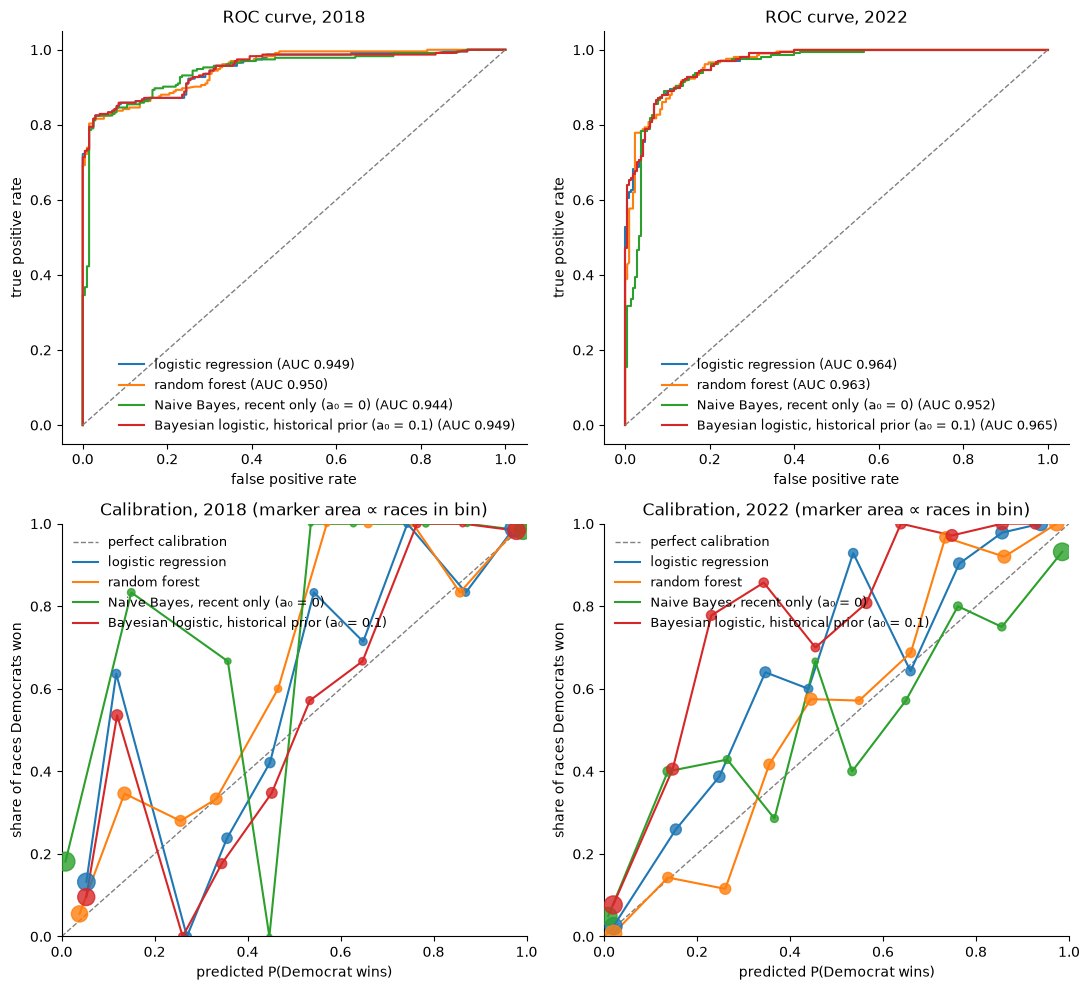

In [30]:
from sklearn.metrics import roc_curve

MAIN = ["logistic regression", "random forest", NB_VARIANTS[best_a0_nb], CLF_VARIANTS[best_a0_clf]]
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for col, (year, data) in enumerate([(TEST_YEAR, test), (STRESS_YEAR, stress)]):
    y = data["dem_win"].to_numpy()
    ax = axes[0, col]
    for name in MAIN:
        fpr, tpr, _ = roc_curve(y, final_preds[year][name])
        ax.plot(fpr, tpr, label=f"{name.replace(' ← selected', '')} (AUC {roc_auc_score(y, final_preds[year][name]):.3f})")
    ax.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1)
    ax.set(title=f"ROC curve, {year}", xlabel="false positive rate", ylabel="true positive rate")
    ax.legend(frameon=False, loc="lower right", fontsize=9)

    ax = axes[1, col]
    ax.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1, label="perfect calibration")
    for name in MAIN:
        reliability(ax, y, final_preds[year][name], name.replace(" ← selected", ""))
    ax.set(title=f"Calibration, {year} (marker area ∝ races in bin)", xlabel="predicted P(Democrat wins)",
           ylabel="share of races Democrats won", xlim=(0, 1), ylim=(0, 1))
    ax.legend(frameon=False, loc="upper left", fontsize=9)
fig.tight_layout(); fig.savefig(FIGS / "final_roc_calibration.png", dpi=150)
plt.show()

The ROC curves nearly coincide: all four models order the races almost identically, so their differences are almost entirely about calibration.

- **2018:** the logistic and random forest calibration curves sit above the diagonal in the middle range, because Democrats won more toss-up races than predicted. Naive Bayes shows its overconfidence most clearly in the lowest bin: among the many races it gave Democrats only about a 1% chance, Democrats actually won nearly one in five.
- **2022:** the selected Bayesian logistic model's curve lies far above the diagonal, because it systematically gave Democrats too little chance. Naive Bayes and the random forest stay closest to the diagonal.

A plausible reason the random forest is consistently well-behaved is that a tree's splits limit how far any one national feature can move a prediction, while a linear score keeps adding national effects without limit.

### 7.1 Vote-margin models

Least squares and LAD give no uncertainty of their own. To compare intervals fairly, least squares also gets the usual Gaussian prediction interval, using the residual SD from its 1978–2014 training data. That is what a standard, non-Bayesian analysis would report.

In [31]:
reg_test, reg_stress = years(reg_df, TEST_YEAR), years(reg_df, STRESS_YEAR)
_, sigma2_pooled = ols_fit(design(reg_train), yr_tr)

def reg_predictions(data):
    X, Xb = data[FEATURES].to_numpy(dtype=float), design(data)
    out = {"least squares": (ols.predict(X), np.full(len(data), np.sqrt(sigma2_pooled))),
           "LAD": (lad.predict(X), None)}
    for a0, label in REG_VARIANTS.items():
        out[label] = predict_bayes_linear(Xb, *bayes_reg[a0], sigma2_recent)
    out["Bayesian, selected a₀, noise from 1978–1998"] = predict_bayes_linear(Xb, *bayes_reg[best_a0_reg], sigma2_hist)
    return out

final_reg_preds = {TEST_YEAR: reg_predictions(reg_test), STRESS_YEAR: reg_predictions(reg_stress)}
NAN_INTERVAL = {"90% interval coverage": np.nan, "90% interval width": np.nan, "NLPD": np.nan}

reg_final = {}
for year, data in [(TEST_YEAR, reg_test), (STRESS_YEAR, reg_stress)]:
    y = data["margin"].to_numpy()
    rows = {"baseline (same margin as last time)": {**reg_metrics(data, data["margin_lag1"].to_numpy()), **NAN_INTERVAL}}
    for name, (mean, sd) in final_reg_preds[year].items():
        rows[name] = {**reg_metrics(data, mean), **(interval_metrics(y, mean, sd) if sd is not None else NAN_INTERVAL)}
    reg_final[year] = pd.DataFrame(rows).T
    reg_final[year].to_csv(RESULTS / f"final_regression_{year}.csv")

print(f"=== {TEST_YEAR} test: {len(reg_test)} contested races ===")
display(reg_final[TEST_YEAR])
print(f"\n=== {STRESS_YEAR} stress test: {len(reg_stress)} contested races ===")
reg_final[STRESS_YEAR]

=== 2018 test: 394 contested races ===


,RMSE,MAE,winner accuracy,winner accuracy (competitive),90% interval coverage,90% interval width,NLPD
baseline (same margin as last time),0.275,0.173,0.873,0.573,NaN,NaN,NaN
least squares,0.164,0.123,0.878,0.584,0.947,0.591,-0.382
LAD,0.161,0.119,0.878,0.584,NaN,NaN,NaN
"Bayesian, historical prior (a₀ = 0.3) ← selected",0.158,0.118,0.881,0.584,0.937,0.550,-0.424
"Bayesian, pooled (a₀ = 1)",0.163,0.123,0.878,0.584,0.924,0.550,-0.396
"Bayesian, recent only (a₀ = 0)",0.154,0.114,0.878,0.573,0.957,0.551,-0.445
"Bayesian, selected a₀, noise from 1978–1998",0.158,0.118,0.881,0.584,0.964,0.607,-0.405



=== 2022 stress test: 391 contested races ===


,RMSE,MAE,winner accuracy,winner accuracy (competitive),90% interval coverage,90% interval width,NLPD
baseline (same margin as last time),0.229,0.144,0.885,0.652,NaN,NaN,NaN
least squares,0.177,0.132,0.893,0.710,0.893,0.591,-0.314
LAD,0.178,0.133,0.893,0.696,NaN,NaN,NaN
"Bayesian, historical prior (a₀ = 0.3) ← selected",0.188,0.141,0.872,0.667,0.877,0.551,-0.237
"Bayesian, pooled (a₀ = 1)",0.178,0.133,0.893,0.710,0.877,0.550,-0.304
"Bayesian, recent only (a₀ = 0)",0.204,0.157,0.864,0.667,0.847,0.551,-0.125
"Bayesian, selected a₀, noise from 1978–1998",0.188,0.141,0.872,0.667,0.893,0.607,-0.251


The vote-margin results follow the same pattern as the classifiers:

- **2018:** the models that lean on recent elections are best. Recent-only Bayesian has an RMSE of about 0.154 and the selected prior about 0.158, against 0.163–0.164 for pooled Bayesian and least squares. The recent-only model also has the best NLPD.
- **2022:** the order reverses. Least squares and pooled Bayesian are best (RMSE about 0.178), and recent-only is worst (about 0.204).
- **Least squares vs. LAD:** the two are indistinguishable on contested races in both years, as on 2016. The outlier robustness of LAD only mattered when uncontested races were in the training data (Section 5.2).

The winner accuracy implied by the predicted margins is close to the classifiers' accuracy, so predicting the margin costs nothing in calling winners.

**Are the intervals honest at every level?** For each nominal level (50%, 80%, 90%, 95%), the plot shows the share of actual margins that fell inside the interval. An honest model sits on the diagonal; above it means intervals that are too wide (underconfident), below means too narrow (overconfident).

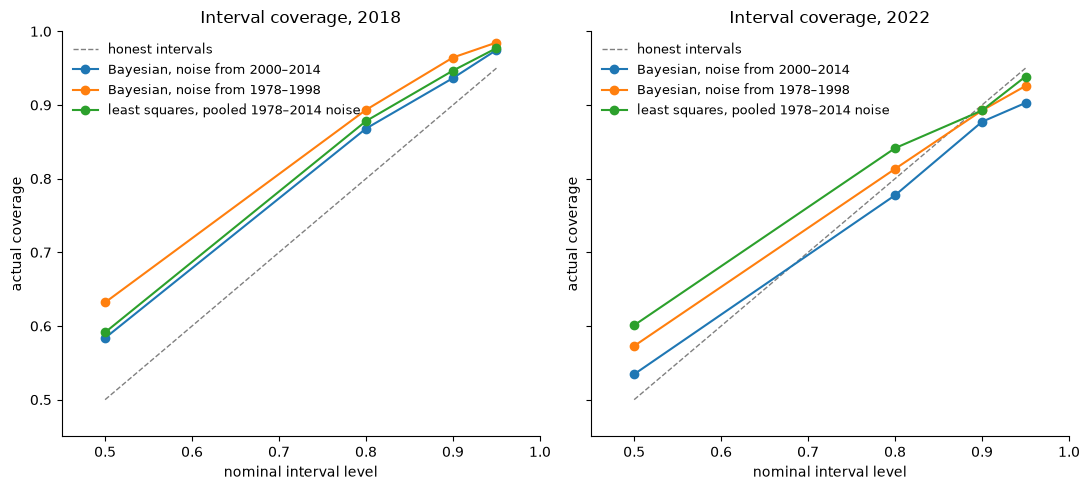

In [32]:
LEVELS = [0.5, 0.8, 0.9, 0.95]
SHOW = {REG_VARIANTS[best_a0_reg]: "Bayesian, noise from 2000–2014",
        "Bayesian, selected a₀, noise from 1978–1998": "Bayesian, noise from 1978–1998",
        "least squares": "least squares, pooled 1978–2014 noise"}

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, (year, data) in zip(axes, [(TEST_YEAR, reg_test), (STRESS_YEAR, reg_stress)]):
    y = data["margin"].to_numpy()
    ax.plot(LEVELS, LEVELS, color="gray", linestyle="--", linewidth=1, label="honest intervals")
    for key, label in SHOW.items():
        mean, sd = final_reg_preds[year][key]
        cov = [interval_metrics(y, mean, sd, lv)[f"{lv:.0%} interval coverage"] for lv in LEVELS]
        ax.plot(LEVELS, cov, marker="o", label=label)
    ax.set(title=f"Interval coverage, {year}", xlabel="nominal interval level", ylabel="actual coverage",
           xlim=(0.45, 1.0), ylim=(0.45, 1.0))
    ax.legend(frameon=False, loc="upper left", fontsize=9)
fig.tight_layout(); fig.savefig(FIGS / "final_interval_coverage.png", dpi=150)
plt.show()

**2018:** every model's intervals are too wide at every level. For example, the 50% intervals contain about 58–63% of actual margins. The Bayesian intervals using recent noise are the least too wide, and those using the older elections' noise are the most, consistent with the exploratory finding.

**2022:** the intervals are close to honest through the middle levels and slightly too narrow at 95%. The post-redistricting election was noisier than recent elections, so the narrower recent-noise intervals now fall a little short.

**The underlying limitation** is that every model uses a single noise level for all races. In reality uncertainty varies a lot: it's much larger when the previous race was uncontested or the district was just redrawn. A model with race-specific noise would fix both the 2018 over-coverage and the 2022 under-coverage.

### 7.2 The research question on held-out elections

A difference in log loss on a few hundred races can easily be noise. To check, the per-race log loss of each selected Bayesian classifier is compared with its own pooled and recent-only variants, and with the two standard classifiers, on the same races, and those races are resampled with replacement 5,000 times (a *paired bootstrap*). If the 95% interval for the difference excludes zero, the difference is unlikely to be luck.

In [33]:
rng = np.random.default_rng(SEED)

def per_race_log_loss(y, p, eps=1e-15):
    p = np.clip(p, eps, 1 - eps)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

def paired_bootstrap(y, p_a, p_b, n_boot=5000):
    d = per_race_log_loss(y, p_a) - per_race_log_loss(y, p_b)
    idx = rng.integers(0, len(d), size=(n_boot, len(d)))
    means = d[idx].mean(axis=1)
    return d.mean(), *np.percentile(means, [2.5, 97.5])

def short(name):
    return name.replace(" ← selected", "")

comparisons = []
for variants, best in [(NB_VARIANTS, best_a0_nb), (CLF_VARIANTS, best_a0_clf)]:
    chosen = variants[best]
    others = [v for a0, v in variants.items() if a0 != best] + ["logistic regression", "random forest"]
    comparisons += [(chosen, other) for other in others]

rows = []
for year, data in [(TEST_YEAR, test), (STRESS_YEAR, stress)]:
    y = data["dem_win"].to_numpy()
    for a, b in comparisons:
        diff, lo, hi = paired_bootstrap(y, final_preds[year][a], final_preds[year][b])
        rows.append({"year": year, "selected model (A)": short(a), "compared with (B)": short(b),
                     "log loss A − B": diff, "95% CI low": lo, "95% CI high": hi,
                     "verdict": "A better" if hi < 0 else ("A worse" if lo > 0 else "no clear difference")})
bootstrap_table = pd.DataFrame(rows)
bootstrap_table.to_csv(RESULTS / "final_bootstrap_log_loss.csv", index=False)
print("Negative difference = the selected model (A) has lower (better) log loss than B.")
bootstrap_table

Negative difference = the selected model (A) has lower (better) log loss than B.


,year,selected model (A),compared with (B),log loss A − B,95% CI low,95% CI high,verdict
0,2018,"Naive Bayes, recent only (a₀ = 0)","Naive Bayes, pooled (a₀ = 1)",0.008,0.003,0.015,A worse
1,2018,"Naive Bayes, recent only (a₀ = 0)",logistic regression,0.295,0.193,0.404,A worse
2,2018,"Naive Bayes, recent only (a₀ = 0)",random forest,0.329,0.218,0.451,A worse
3,2018,"Bayesian logistic, historical prior (a₀ = 0.1)","Bayesian logistic, pooled (a₀ = 1)",-0.006,-0.013,-0.000,A better
4,2018,"Bayesian logistic, historical prior (a₀ = 0.1)","Bayesian logistic, recent only (a₀ = 0)",0.003,-0.001,0.006,no clear difference
5,2018,"Bayesian logistic, historical prior (a₀ = 0.1)",logistic regression,-0.007,-0.013,-0.001,A better
6,2018,"Bayesian logistic, historical prior (a₀ = 0.1)",random forest,0.028,0.010,0.047,A worse
7,2022,"Naive Bayes, recent only (a₀ = 0)","Naive Bayes, pooled (a₀ = 1)",0.011,0.005,0.018,A worse
8,2022,"Naive Bayes, recent only (a₀ = 0)",logistic regression,0.057,-0.018,0.147,no clear difference
9,2022,"Naive Bayes, recent only (a₀ = 0)",random forest,0.087,0.011,0.168,A worse


**Naive Bayes:** in both years, the validation choice (recent only) is reliably but slightly worse than pooling. Naive Bayes is reliably worse than the random forest in both years, and worse than logistic regression in 2018.

**Bayesian logistic regression:**
- **2018:** the selected prior weight is borderline better than pooling (the interval's upper end is essentially zero, so a different bootstrap draw could call it either way). It is indistinguishable from recent-only, better than the scikit-learn logistic regression, and worse than the random forest.
- **2022:** it is reliably worse than every alternative except the recent-only variant, which it beats. Down-weighting history caused real, not random, damage on the unusual election.

**Across both Bayesian classifiers,** giving the older elections full weight (pooling) was clearly better than the validation-selected weight in three of the four comparisons, and borderline worse in the fourth (Bayesian logistic regression on 2018).

## 8. Discussion and conclusion

### Summary of findings

1. **Past results carry most of the signal.** Incumbency and the previous margin dominate every model, and the "same party wins again" baseline is very hard to beat on labels: in 2018 the best models beat it by about one race in two hundred, and in 2016 and 2022 none beat it at all. Where the models add real value is in their **probabilities**. They rank races almost perfectly (ROC AUC 0.94–0.99) and say how likely an upset is, which the baseline cannot.
2. **The random forest was the best classifier** on validation and on both held-out elections. The bootstrap shows its advantage is real, not luck. Bagging and random feature selection (Lecture 12) kept it stable: the fully grown single-race-leaf forest overfit badly, but moderate depth worked well.
3. **Naive Bayes illustrates both lessons from Lecture 14.** Its ranking was nearly as good as the other models', but because its naive assumption counts correlated evidence (two previous margins and incumbency) several times, its probabilities were overconfident, which was very costly in 2018. Because it largely ignores national conditions, it nailed the near-neutral 2022 seat total and badly missed the 2018 wave.
4. **Least squares and LAD perform the same on contested races.** But when uncontested races (margins of ±1) were left in training, least squares' error grew much more than LAD's, a real-world replication of the outlier example from Lecture 4.
5. **Uncertainty was off in a predictable way.** The logistic classifiers were underconfident on 2016, and the regression intervals were too wide in 2016 and 2018 but about right (slightly too narrow at 95%) in the noisier 2022 election. Both follow from the exploratory finding that elections have become more predictable, combined with a single noise level for all races.

### Answer to the research question

*Does using older elections as a prior produce better-calibrated forecasts than pooling all the data together?*

**Not in this project: on the held-out elections, giving the older elections full weight (pooling) was as good or better in almost every comparison.**

- **When the eras agree,** as for the incumbency hold rate (Section 4.3), the historical prior simply adds precision.
- **District-level effects** (incumbency, previous margins) are estimated from thousands of races in every era, and they were similar across eras. Down-weighting the older elections helped slightly on 2016, and for the logistic and linear models on 2018. But the gains were small, and for Naive Bayes pooling was better in both test years.
- **National-level effects** (the midterm penalty, redistricting) are estimated from only a handful of elections, and the older elections roughly double that handful. Down-weighting them left Bayesian logistic regression relying on four midterms and two redistricting cycles from 2000–2014, which produced extreme estimates and a badly wrong 2022 forecast. Pooling was far more robust.

**The historical prior was most valuable exactly where recent data was thinnest, and that was also where the validation election could not detect it.** 2016 was a presidential year without redistricting, so tuning the prior weight on it effectively ignored the national-level effects.

### Lessons

- **The validation set must resemble the conditions being forecast.** A single presidential-year validation election could not reveal how the models would behave in a redistricting midterm. Rotating through several past elections, including midterms, would have given a more reliable choice of prior weight. (The design here was fixed before the test results were seen, and it was not changed afterward.)
- **Independence assumptions overstate certainty.** Naive Bayes treated correlated features as independent evidence, and the Bayesian logistic intervals (Section 4.5) treated thousands of races as independent evidence about the midterm penalty, when the real evidence is a few elections. Both made the models more confident than the data justified.

### Limitations

- **Redistricting:** after each census, `margin_lag1` describes a differently drawn district, which is the reason 2022 is a stress test. Mid-decade redraws in individual states are not flagged.
- **Incumbent matching** is by first initial and last name, so an incumbent who moved to a new district after redistricting counts as an open seat.
- **Excluded races:** 12 third-party wins are excluded throughout, and uncontested races are excluded from the regression models.
- **Limited features:** the models use only past results and national context. They have no candidate quality, fundraising, or polling, which is why they missed the size of the 2018 wave.
- **One noise level for all races:** the regression intervals use a single noise level, although uncertainty clearly varies by race.
- **A small number of elections:** the evaluation rests on one validation election, one test election, and one stress test, so conclusions about election-level effects come from very few examples.

### Future work

- **A hierarchical Bayesian model** with a shared swing term for each election. This would make the uncertainty about national effects honest by treating each election, not each race, as the unit of evidence for those effects.
- **Separate prior weights** for district-level and national-level parameters: a weak prior where recent data is plentiful, and a strong one where it is scarce.
- **Race-specific noise**, larger for previously uncontested and newly redrawn districts.
- **Additional features:** district-level presidential vote, which is especially useful after redistricting, and a national-environment measure such as generic-ballot polling.

### Conclusion

Using only past results and national context, all of the models forecast House races with high accuracy and near-perfect ranking, though none clearly beat the simple baseline at calling winners. The random forest gave the best-calibrated probabilities throughout. The Bayesian framework from the lectures, priors built from pseudo-counts of past elections, made the research question concrete by turning "how much should older elections count?" into a single tunable weight. The answer: recent elections describe districts slightly better, but older elections are essential for the rare, election-level conditions that a short recent history cannot pin down. In this project, the safest choice was to let them count fully.

## 9. References

**Data**
- MIT Election Data and Science Lab, “U.S. House 1976&ndash;2024.” Harvard Dataverse, 2017. doi: 10.7910/DVN/IG0UN2. 

**Methods beyond the course lectures**
- Bishop, C. M. (2006). *Pattern Recognition and Machine Learning*. Springer. Section 3.3 (Bayesian linear regression) and Sections 4.4–4.5 (the Laplace approximation and Bayesian logistic regression, including the probit approximation to the predictive distribution).
- Ibrahim, J. G., & Chen, M.-H. (2000). Power prior distributions for regression models. *Statistical Science*, 15(1), 46–60. The basis for weighting historical data by a₀.
- MacKay, D. J. C. (1992). The evidence framework applied to classification networks. *Neural Computation*, 4(5), 720–736. The probit approximation σ(μ / √(1 + πs²/8)).

**Models and software**
- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.

**Course materials**
- Vosoughi, S. COSC 274 lecture slides, Dartmouth College, Fall 2026: validation and test methodology (Lecture 3), linear regression, gradient descent, and least absolute deviations (Lecture 4), regularization (Lecture 5), logistic regression and cross-entropy (Lecture 6), classification metrics (Lecture 7), random forests and Bayes' rule (Lecture 12), and Bayesian learning and Naive Bayes (Lectures 13–14).